In [1]:
import pandas as pd
import numpy as np
from pprint import pprint
import time
import os
import matplotlib.pyplot as plt
from typing import *
import math

plt.rcParams["figure.figsize"] = (20,3)

In [71]:
def createRegionMap(scores: dict, title: str = "Score du modèle par région"):
    import geopandas as gpd
    import matplotlib.colors as mcolors

    # --- Chargement du GeoJSON des régions françaises ---
    # url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson"
    # response = requests.get(url)
    gdf = gpd.read_file("regions-version-simplifiee.geojson.txt")

    # --- Correspondance des noms (normalisation) ---
    # Le GeoJSON utilise parfois des noms légèrement différents
    rename_map = {
        "Provence-Alpes-Côte d'Azur": "PACA",  # adapter selon tes clés
    }
    # gdf["nom_model"] = gdf["nom"].replace(rename_map)
    gdf["nom_model"] = gdf["nom"].replace(rename_map)

    # --- Ajout des scores au GeoDataFrame ---
    gdf["score"] = gdf["nom_model"].map(scores)

    # --- Colormap rouge → vert ---
    cmap = mcolors.LinearSegmentedColormap.from_list(
        "score_cmap", ["#e74c3c", "#f39c12", "#2ecc71"]
    )

    # --- Normalisation des scores pour la colormap ---
    # vmin = min(scores.values())
    # vmax = max(scores.values())
    vmin = min(min(scores.values()),0.5)
    vmax = 1
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # --- Figure ---
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=16, fontweight="bold", pad=20)

    # --- Régions sans score (gris) ---
    gdf[gdf["score"].isna()].plot(ax=ax, color="#cccccc", edgecolor="white", linewidth=0.8)

    # --- Régions avec score (dégradé) ---
    gdf[gdf["score"].notna()].plot(
        ax=ax,
        column="score",
        cmap=cmap,
        norm=norm,
        edgecolor="white",
        linewidth=0.8,
    )

    # --- Labels : nom + score au centroïde de chaque région ---
    for _, row in gdf[gdf["score"].notna()].iterrows():
        centroid = row.geometry.centroid
        score_val = row["score"]
        nom_affiche = row["nom_model"]

        # Couleur du texte selon la luminosité du fond
        bg_color = cmap(norm(score_val))
        luminance = 0.299*bg_color[0] + 0.587*bg_color[1] + 0.114*bg_color[2]
        text_color = "white" if luminance < 0.5 else "#1a1a1a"

        ax.annotate(
            f"{nom_affiche}\n{score_val:.4f}",
            xy=(centroid.x, centroid.y),
            ha="center", va="center",
            fontsize=7.5, fontweight="bold",
            color=text_color,
        )

    # --- Colorbar ---
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("Score R²", fontsize=11)
    cbar.ax.tick_params(labelsize=9)

    plt.tight_layout()
    plt.show()

In [65]:
#* Constants
startingDate = "2020-01-01"
endingDate = "2023-12-31"

#* Format des données horraires
startingDateInt = "2020010100"
endingDateInt = "2023123123"
regions_departements = {
    "Auvergne-Rhône-Alpes": [
        1, 3, 7, 15, 26, 38, 42, 43, 63, 69, 73, 74
    ],
    "Bourgogne-Franche-Comté": [
        21, 25, 39, 58, 70, 71, 89, 90
    ],
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": [
        18, 28, 36, 37, 41, 45
    ],
    # "Corse": [ #* Not in Rte Data
    #     20
    # ],
    "Grand Est": [
        8, 10, 51, 52, 54, 55, 57, 67, 68, 88
    ],
    "Hauts-de-France": [
        2, 59, 60, 62, 80
    ],
    "Île-de-France": [
        75, 77, 78, 91, 92, 93, 94, 95
    ],
    "Nouvelle-Aquitaine": [
        16, 17, 19, 23, 24, 33, 40, 47, 64, 79, 86, 87
    ],
    "Normandie": [
        14, 27, 50, 61, 76
    ],
    "Occitanie": [
        9, 11, 12, 30, 31, 32, 34, 46, 48, 65, 66, 81, 82
    ],
    "Pays de la Loire": [
        44, 49, 53, 72, 85
    ],
    "PACA": [
        4, 5, 6, 13, 83, 84
    ]
}


In [3]:
def getFileNameMet(step:Literal["raw","cleaned"],delta:Literal["ByDay","ByHour"]=None,departementNumber:int=None):
    metoBase = "meteo_"
    number = str(departementNumber).zfill(2)

    return os.path.join(step+"Data","meteo",delta,metoBase+number+".csv")

def getFileNameEnr(step:Literal["raw","cleaned"],region:str=None,year:int=None):
    if step=="raw":
        # print(os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.zip"))
        return os.path.join(step+"Data","energy",f"eCO2mix_RTE_{region.replace(" ","-")}_Annuel-Definitif_{year}.xls")
    else:
        return os.path.join(step+"Data","energy",f"Consommation_{region.replace(" ","-")}.csv")

In [4]:
def getEnrData(region:str):
    return pd.read_csv(getFileNameEnr("cleaned",region=region),parse_dates=["Date"])

def getMetData(delta:Literal["ByDay","ByHour"],dep:int):
    return pd.read_csv(getFileNameMet("cleaned",delta,dep),parse_dates=["DATE"])

**MOYENNE PAR REGION**

In [ ]:
#* Check if there exist a correlation

for region,deps in regions_departements.items():


    energyData = pd.read_csv(getFileNameEnr("cleaned",region=region),parse_dates=["Date"])
    # print(energyData)
    # energyData["Consommation"] = energyData["Consommation"] / 10_000
    # energyData["Date"] = pd.to_datetime(energyData["Date"],format="%m/%d/%Y")
    energyData = energyData.sort_values("Date")
    # energyData = energyData.set_index("Date")

    departementsData = []
    for dep in deps: 
        # print(dep)
        depDf = pd.read_csv(getFileNameMet("cleaned","ByDay",dep),parse_dates=["DATE"])
        depDf = depDf[(depDf["DATE"] >= energyData["Date"].min()) & (depDf["DATE"] <= energyData["Date"].max())]
        departementsData.append(depDf)

    # departementsData = [pd.read_csv(getFileNameMet("cleaned","ByDay",dep)) for dep in deps]
    # print(departementsData[0].head())
    departementUnited = pd.concat(departementsData)
    # departementUnited
    regionAverage = departementUnited.groupby(["DATE"]).mean() #* Somme sur les heures
    regionAverage["DATE"] = pd.to_datetime(regionAverage.index)
    # print("avt drop na",regionAverage.shape)
    regionAverage = regionAverage.dropna(subset=["TM"])
    # print("apr drop na",regionAverage.shape)
    

    plt.plot(regionAverage['DATE'],regionAverage["TM"],label="Température")
    plt.plot(energyData['Date'],energyData["Consommation"],label="Consommation",linewidth=0.2)
    plt.title(region)
    plt.legend()
    plt.show()

In [6]:
def generateDoublePlot(x1,y1,x2,y2,label1,label2):
    # --- Axes doubles ---
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax2 = ax1.twinx()  # Deuxième axe Y qui partage le même axe X

    ax1.plot(x1, y1, color="tomato", label=label1)
    ax2.plot(x2, y2, color="steelblue", label=label2, linewidth=1)

    # Légendes combinées des deux axes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

    ax1.set_ylabel(label1, color="tomato")
    ax2.set_ylabel(label2, color="steelblue")
    ax1.tick_params(axis="y", colors="tomato")
    ax2.tick_params(axis="y", colors="steelblue")

    plt.title(region)
    plt.tight_layout()
    plt.show()

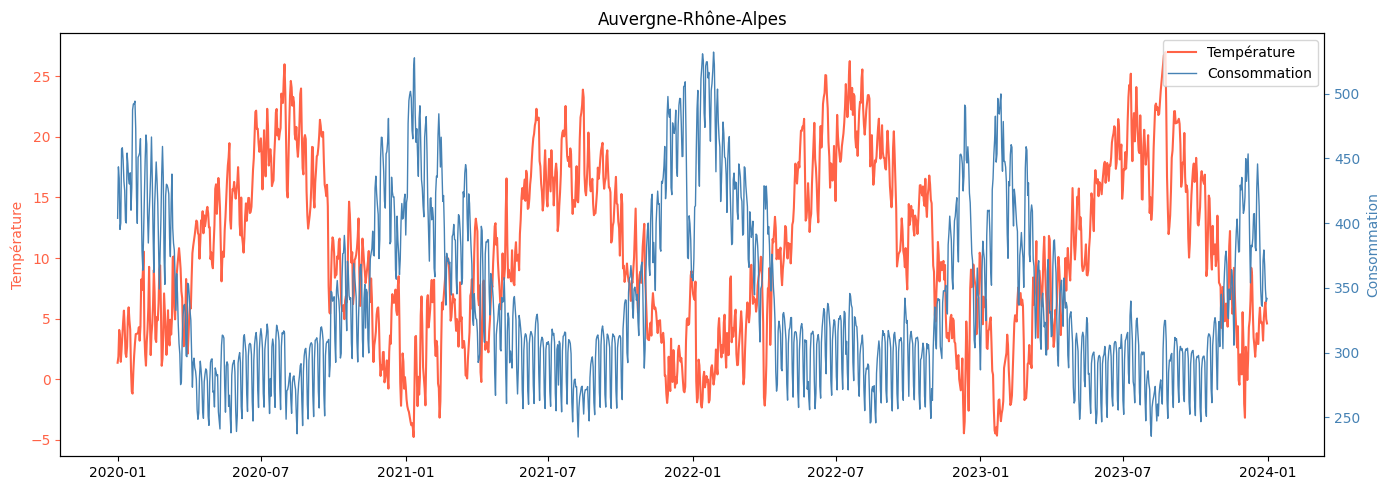

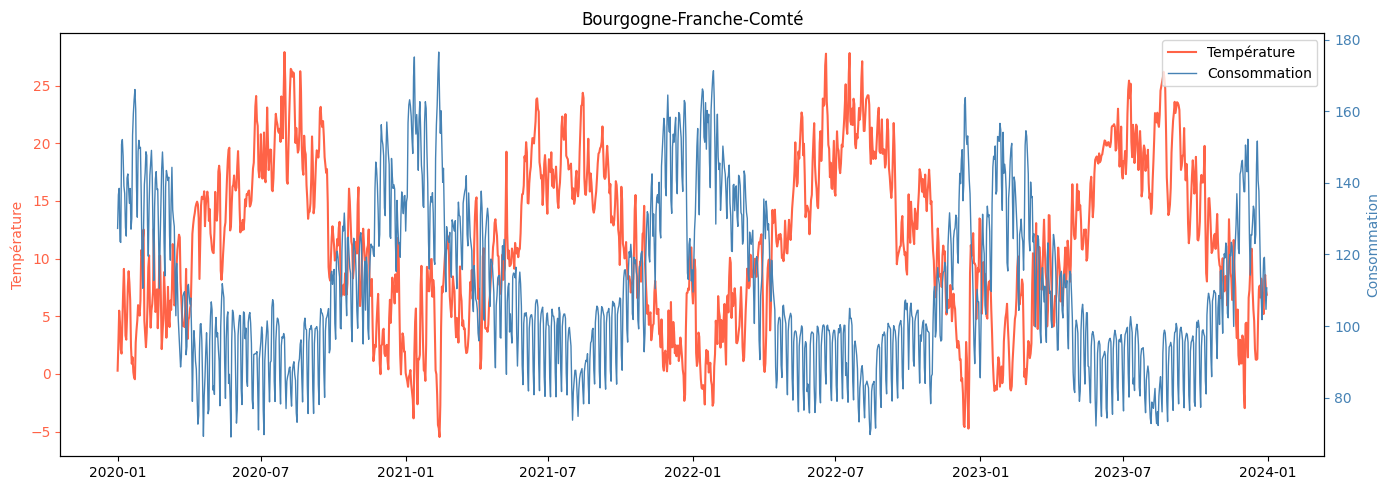

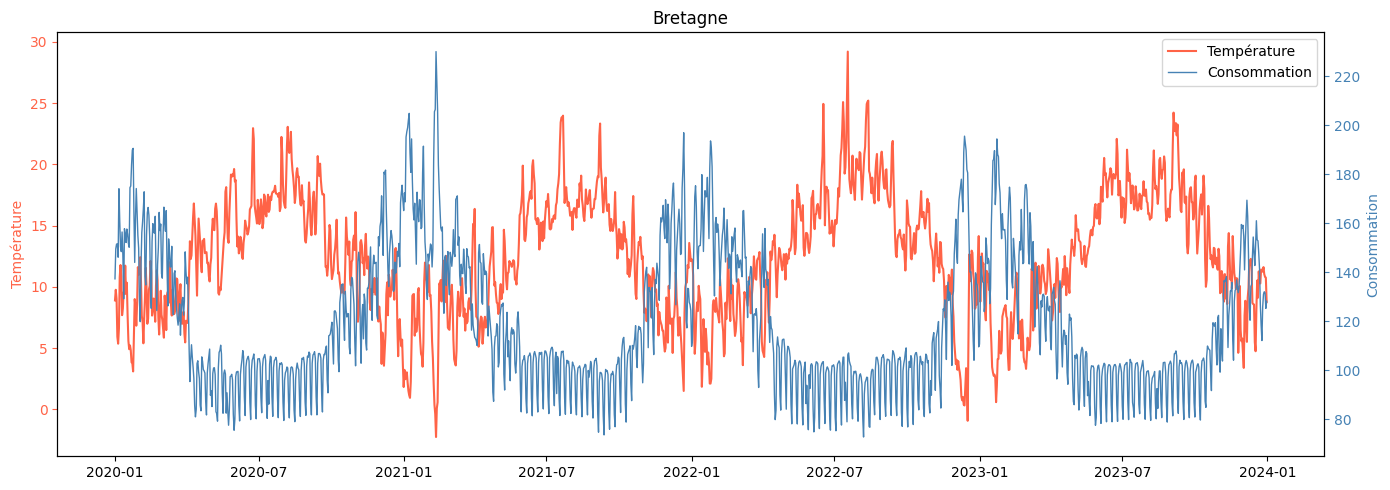

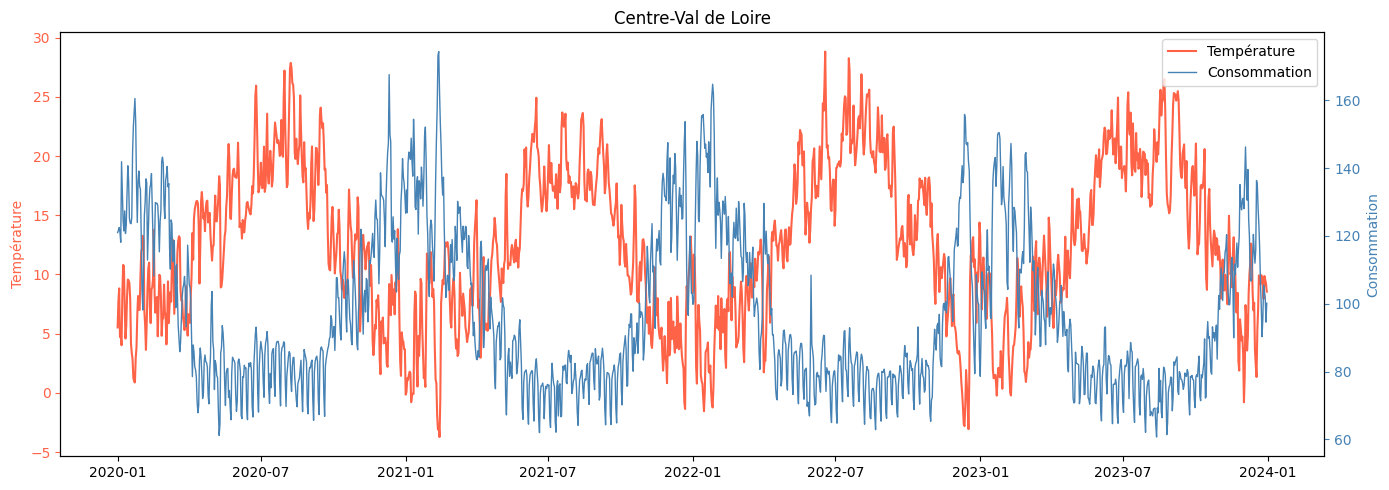

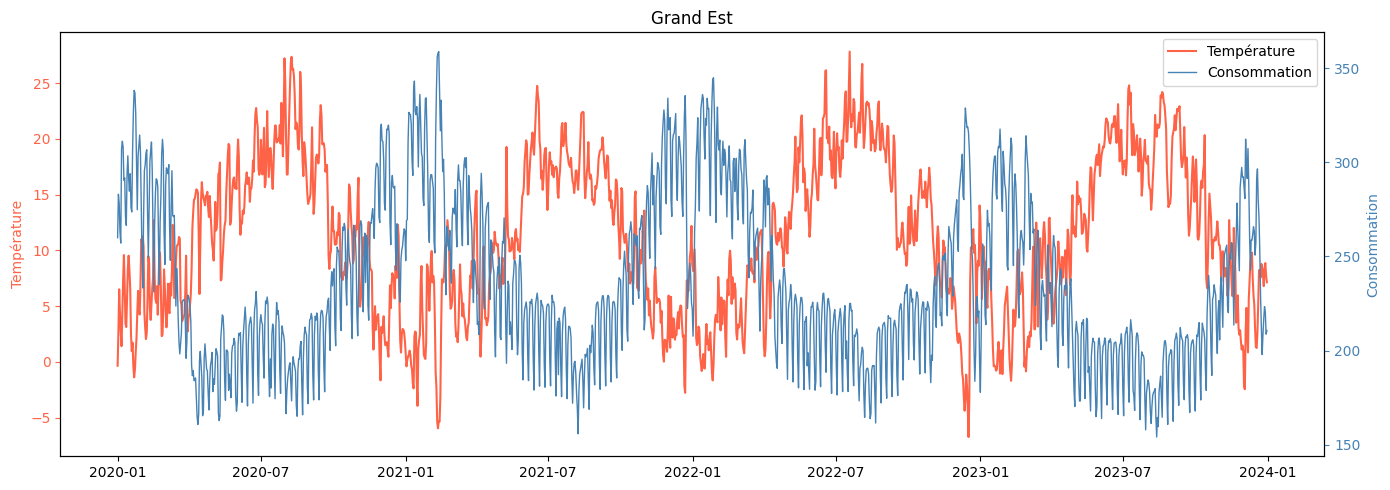

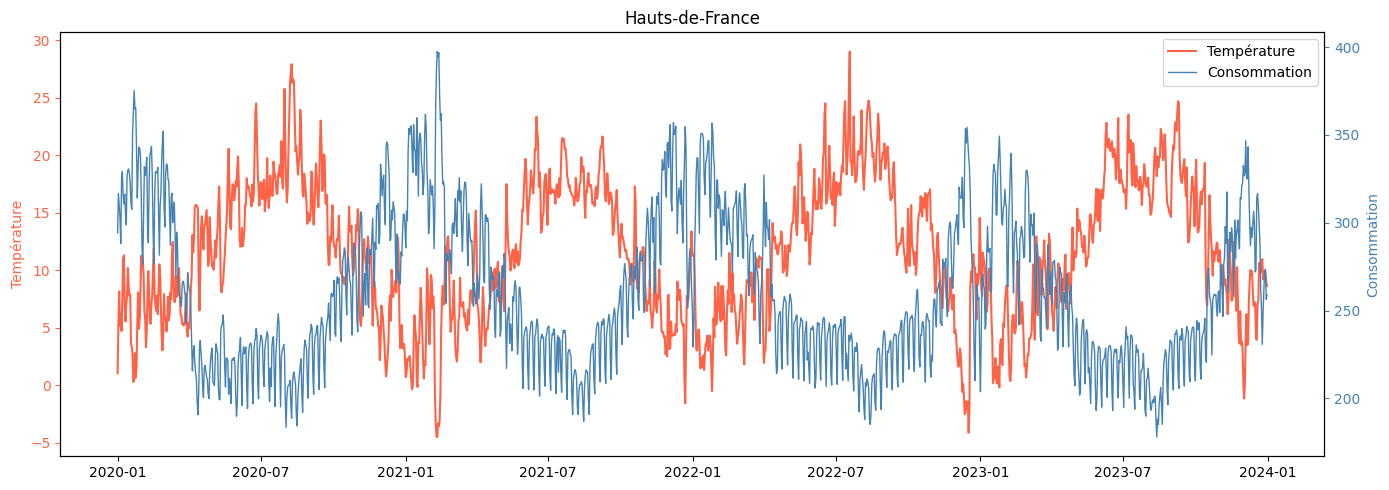

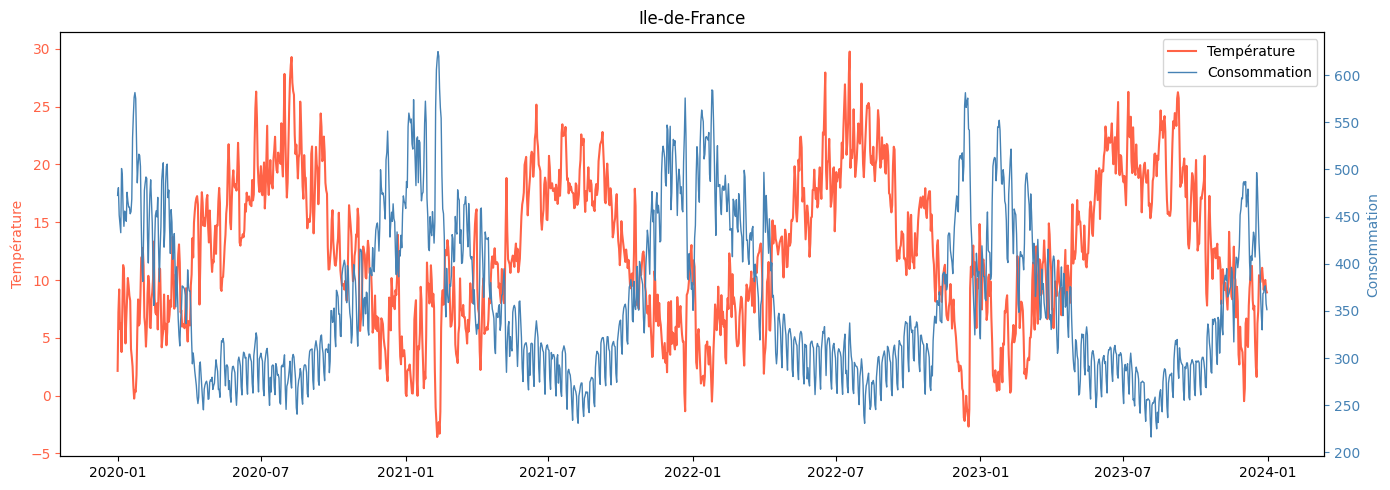

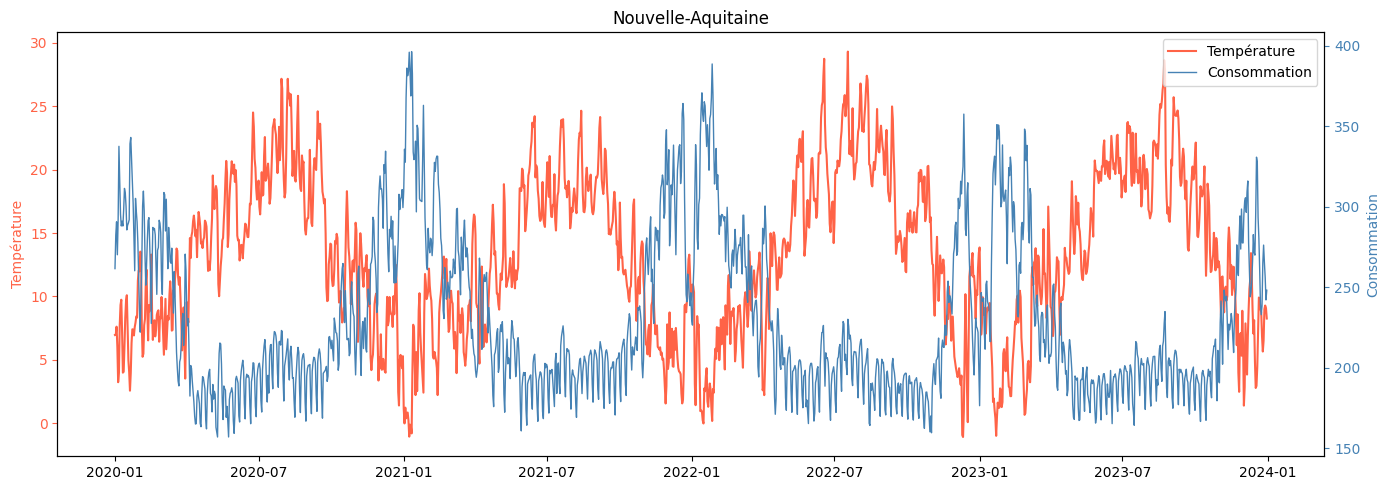

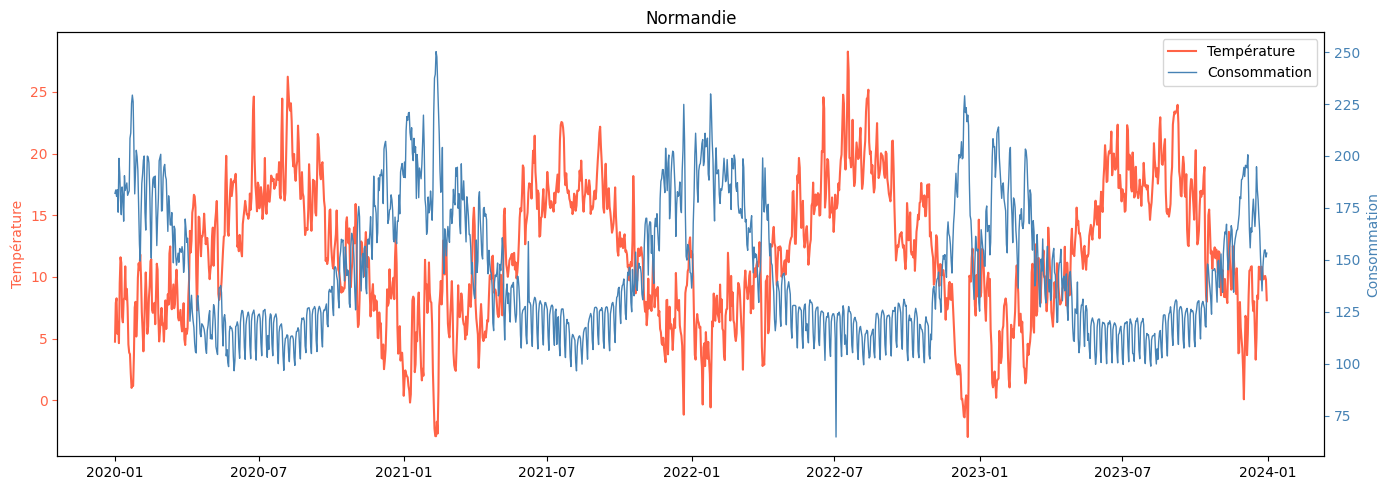

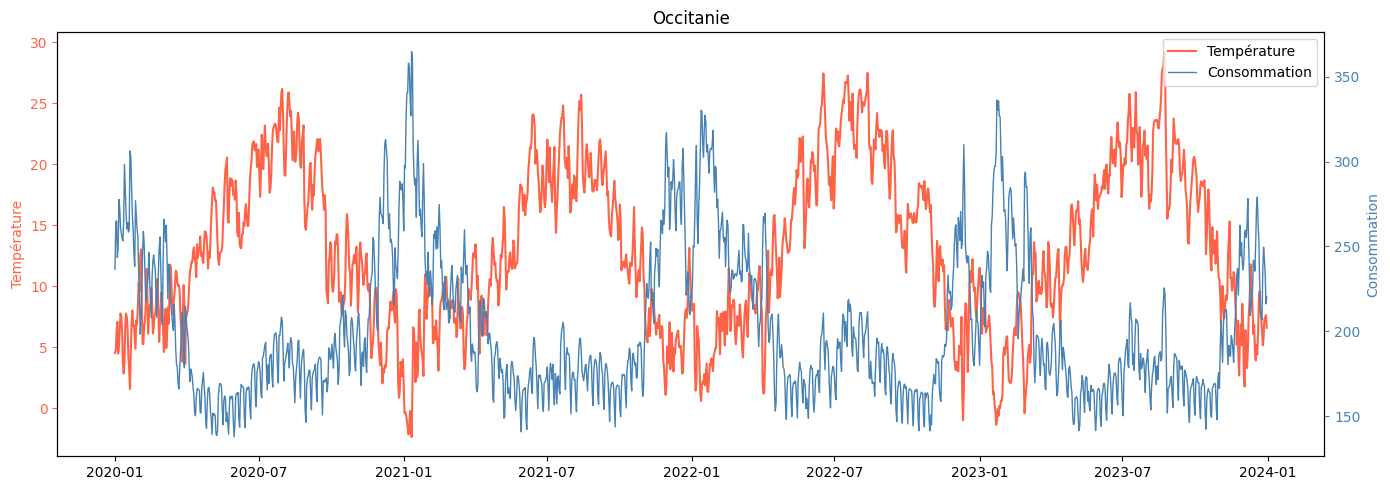

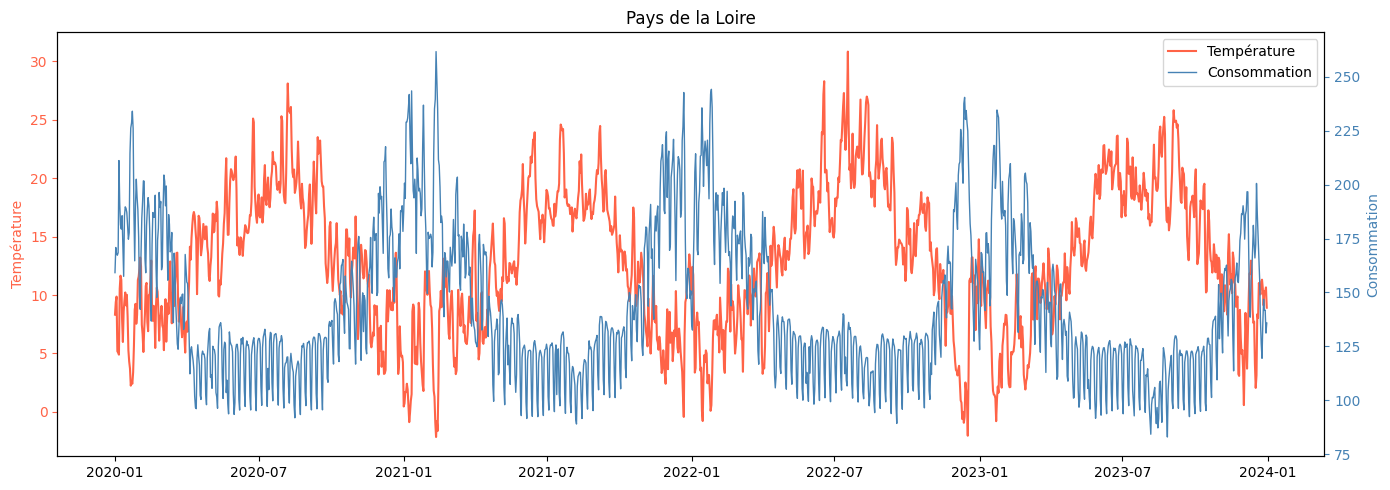

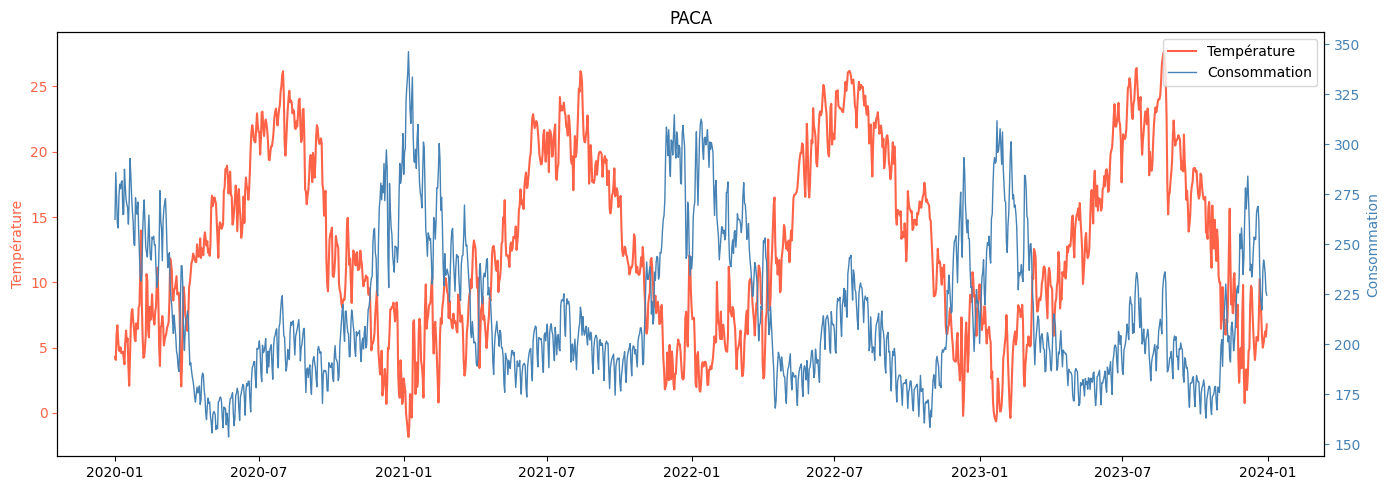

In [8]:
plotStartDate = "2020-01-01"
plotEndDate = "2023-12-31"
for region, deps in regions_departements.items():

    energyData = pd.read_csv(getFileNameEnr("cleaned", region=region), parse_dates=["Date"])
    energyData = energyData.sort_values("Date")
    energyData = energyData[(energyData["Date"] >= plotStartDate) & (energyData["Date"] <= plotEndDate)]
    
    energyData = energyData.groupby("Date").sum()
    
    departementsData = []
    for dep in deps:
        depDf = pd.read_csv(getFileNameMet("cleaned", "ByDay", dep), parse_dates=["DATE"])
        depDf = depDf[(depDf["DATE"] >= plotStartDate) & (depDf["DATE"] <= plotEndDate)]
        departementsData.append(depDf)

    departementUnited = pd.concat(departementsData)
    regionAverage = departementUnited.groupby("DATE").mean()
    regionAverage = regionAverage.dropna(subset=["TM"])
    # print(energyData)
    generateDoublePlot(regionAverage.index,regionAverage["TM"],energyData.index,energyData["Consommation"],"Température","Consommation")


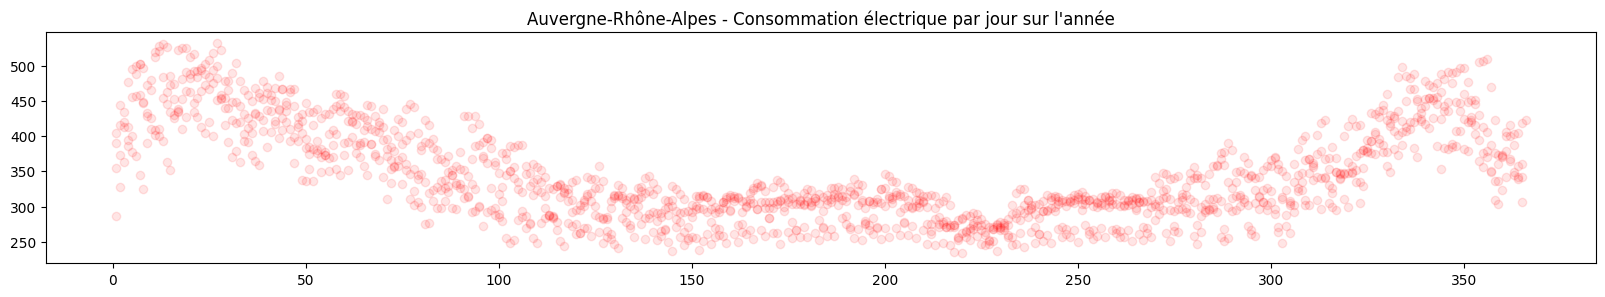

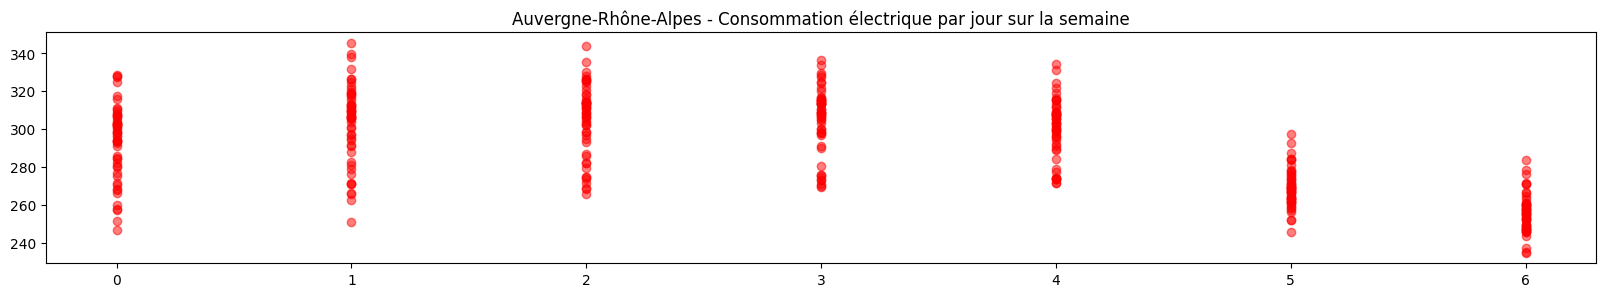

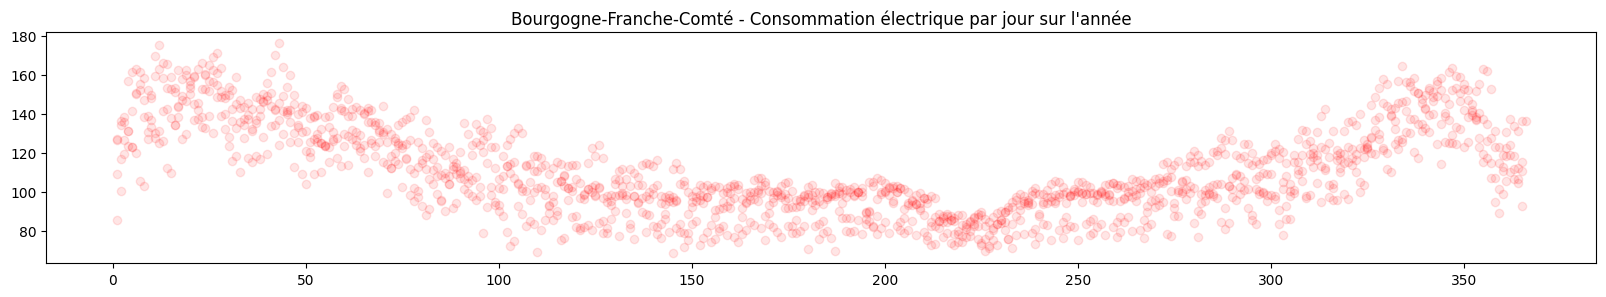

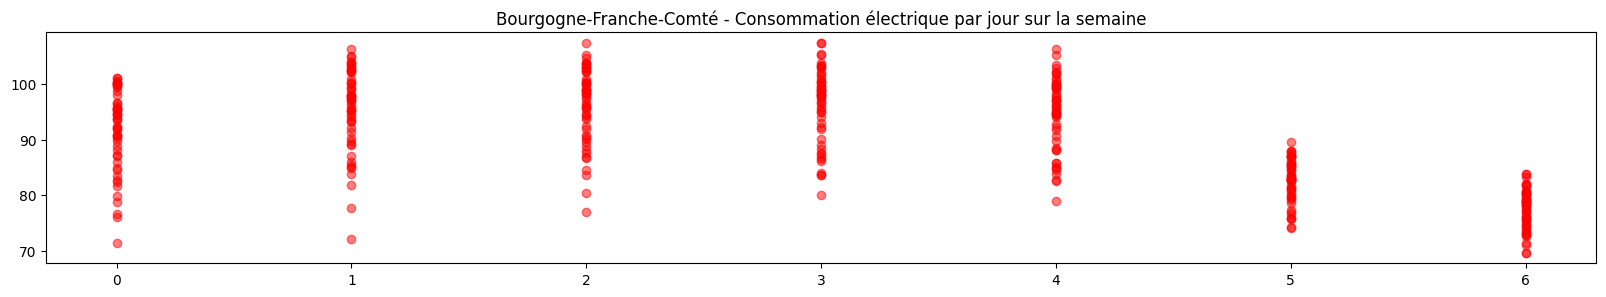

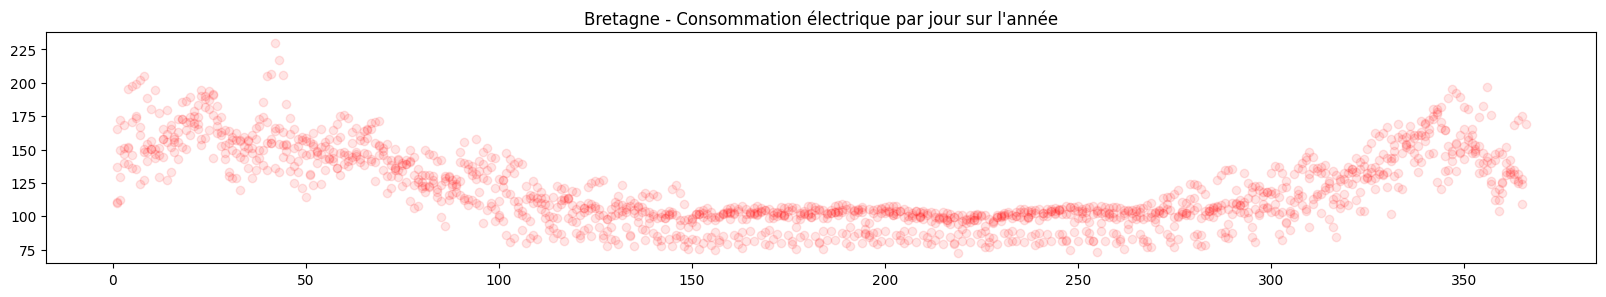

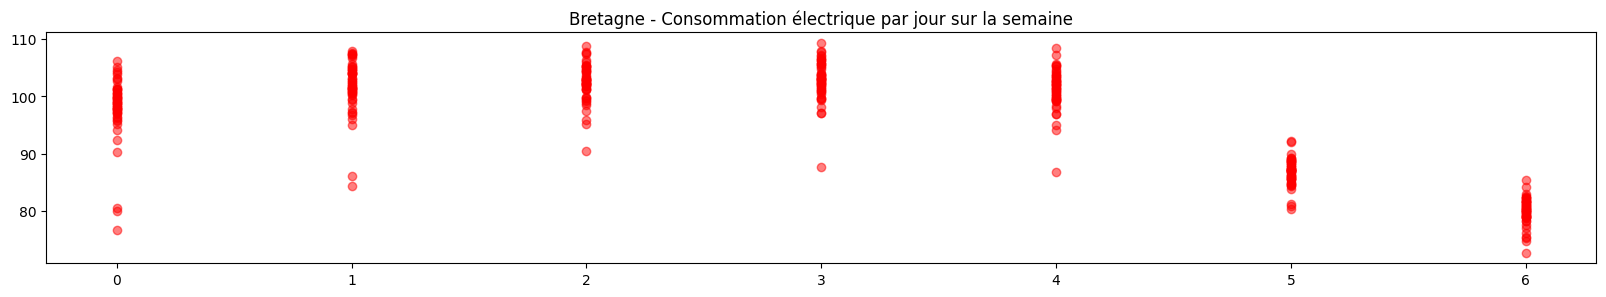

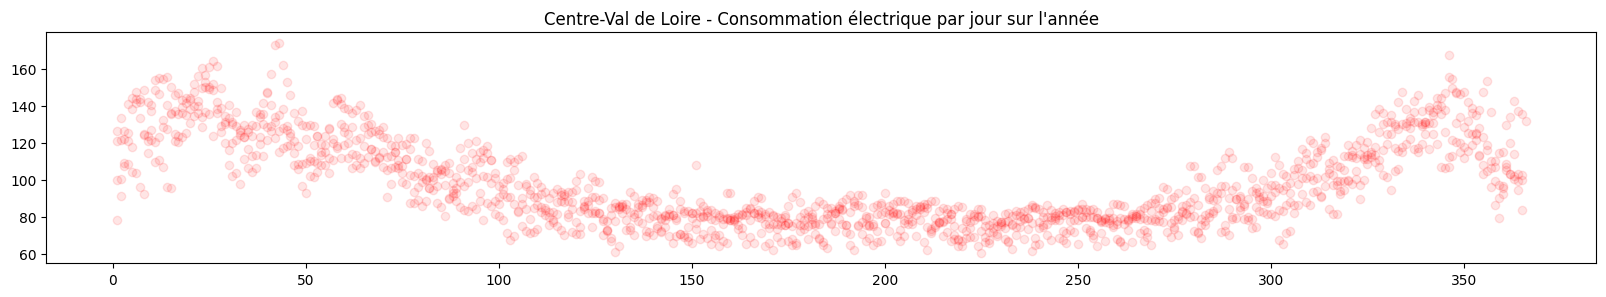

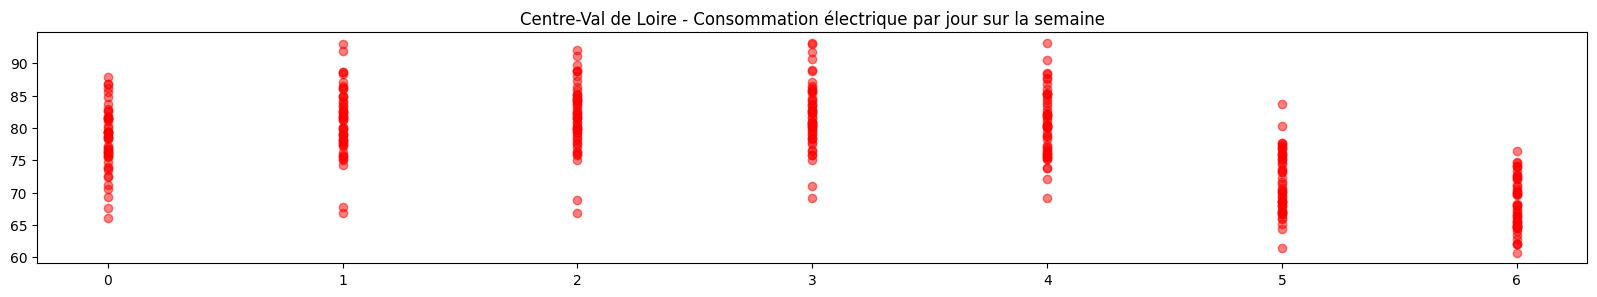

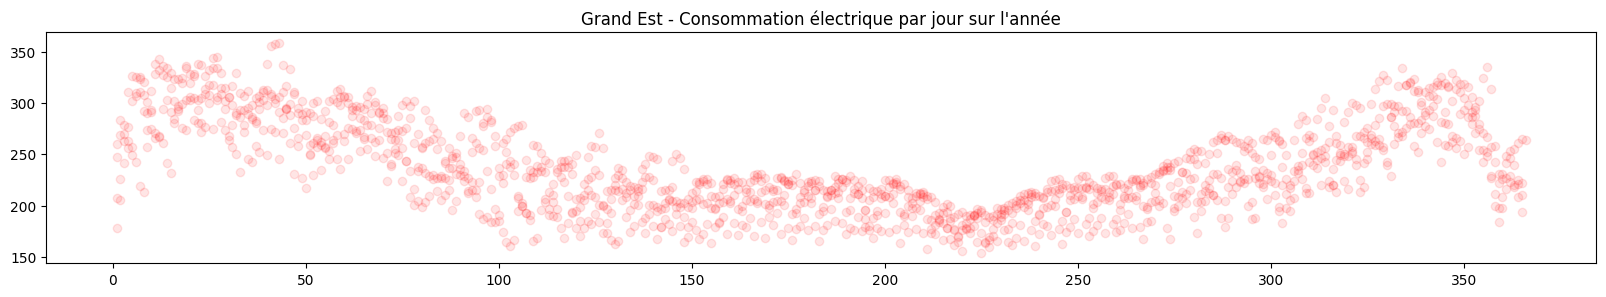

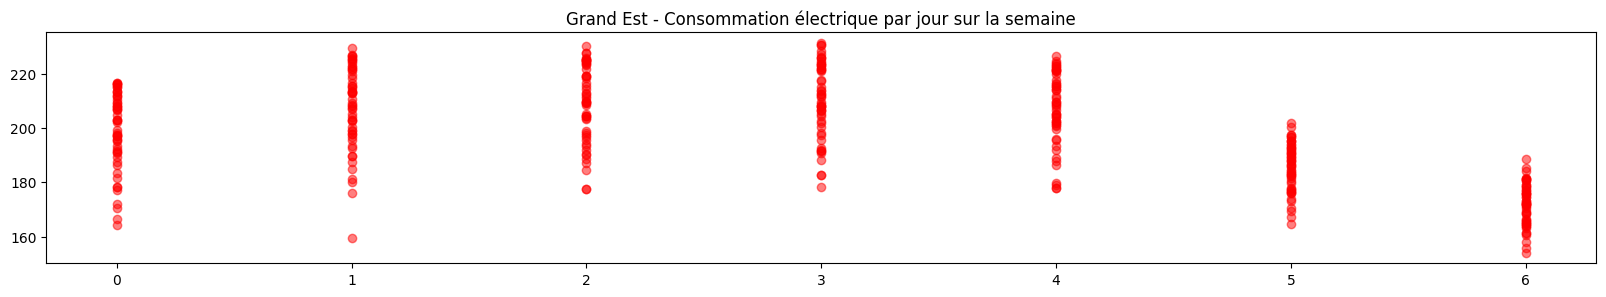

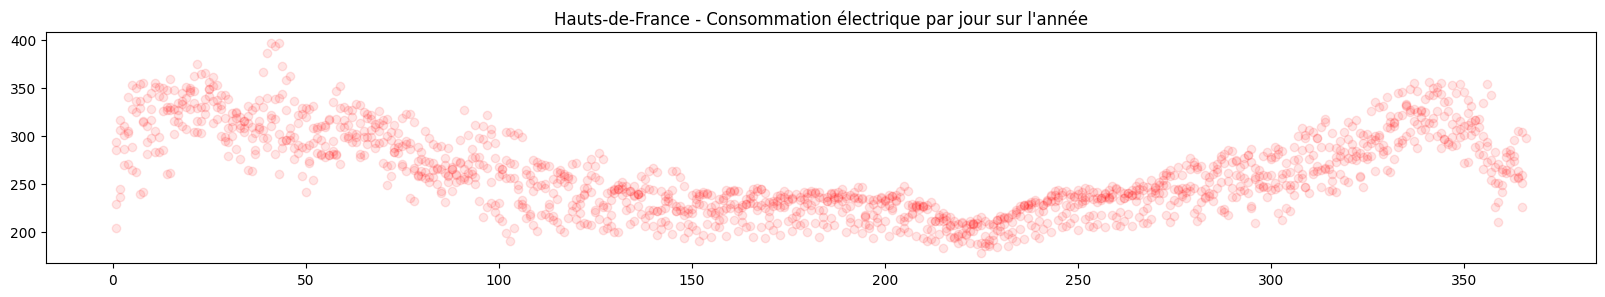

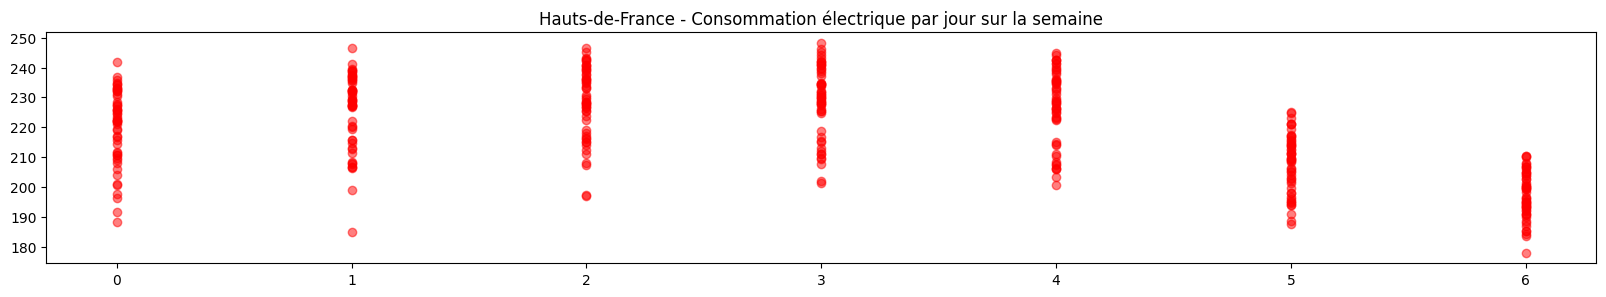

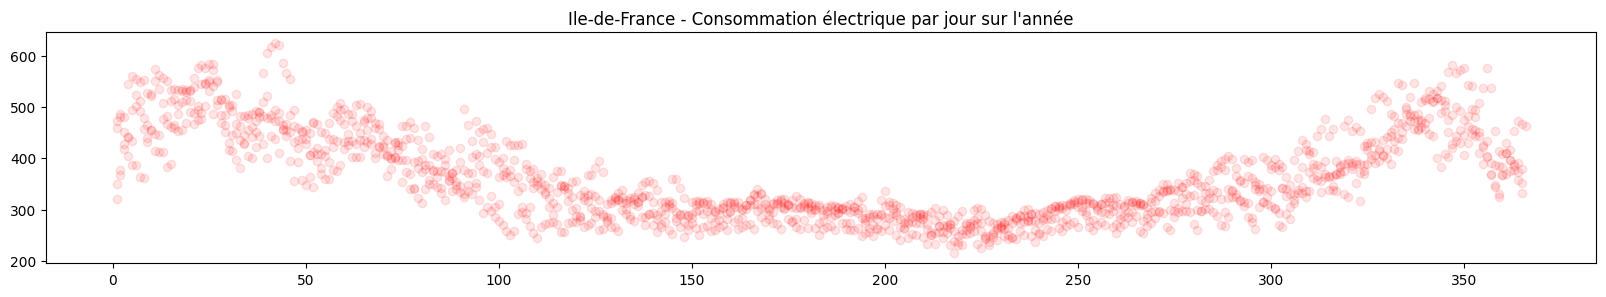

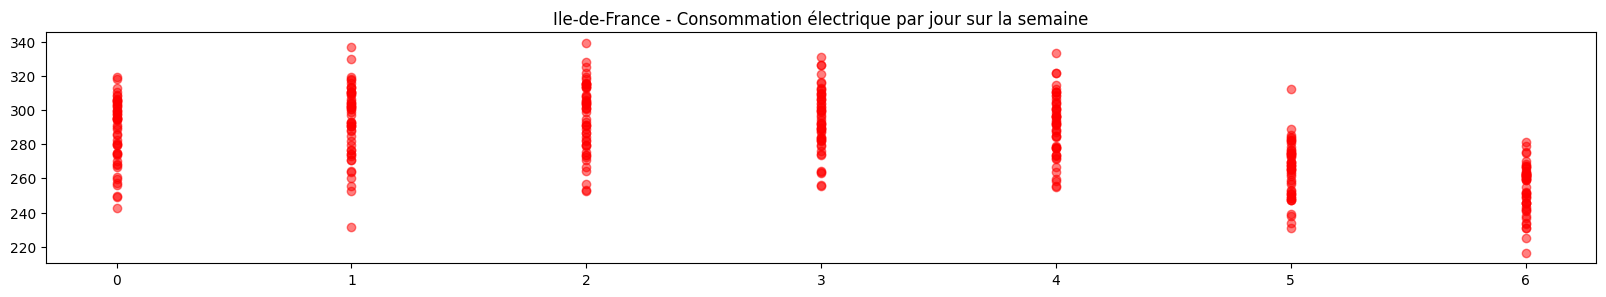

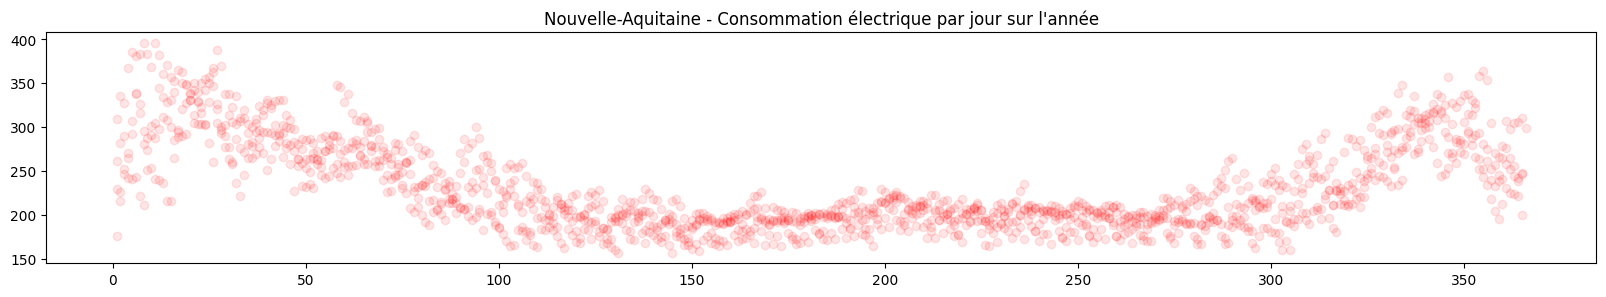

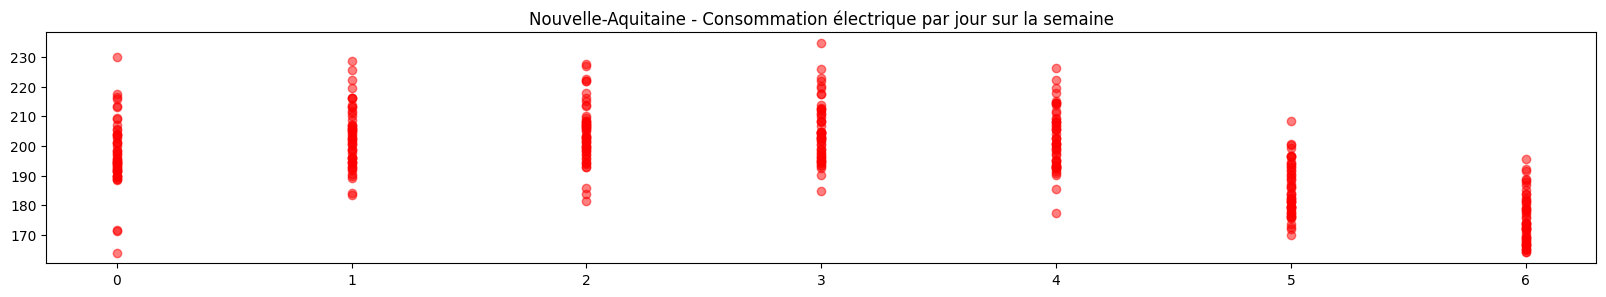

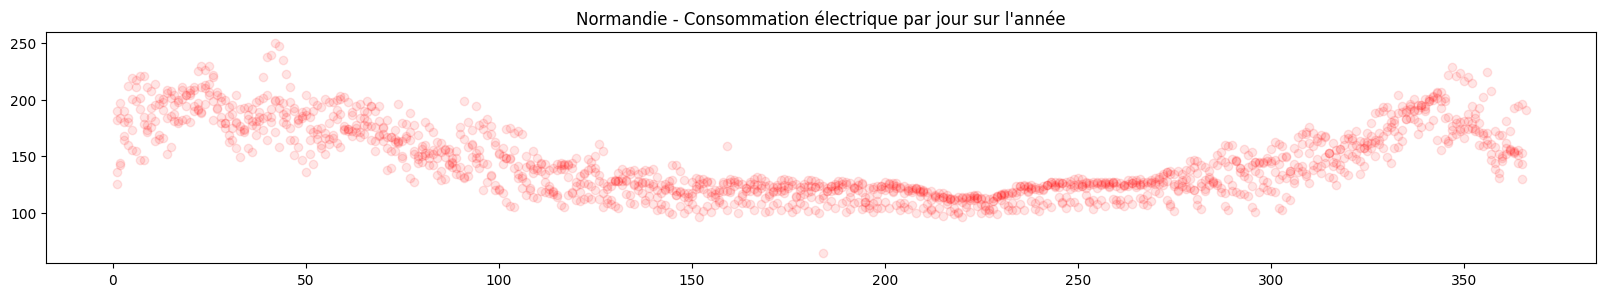

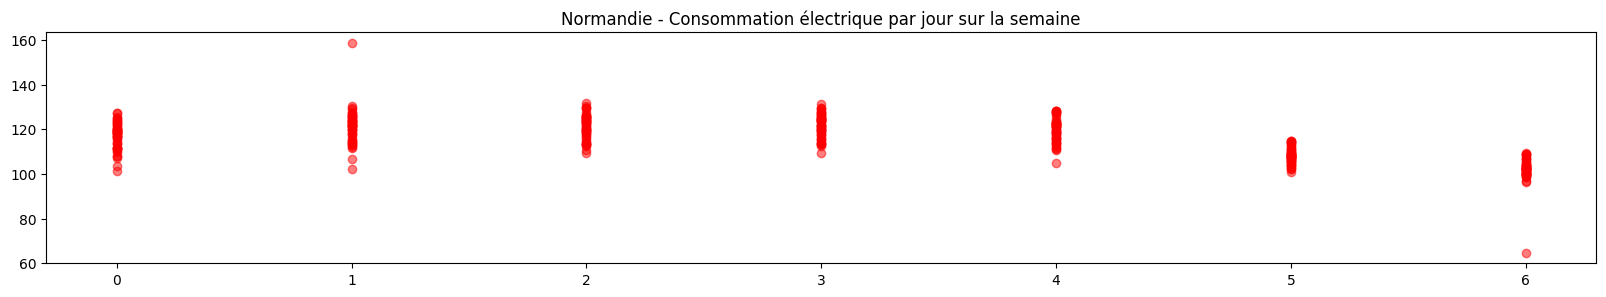

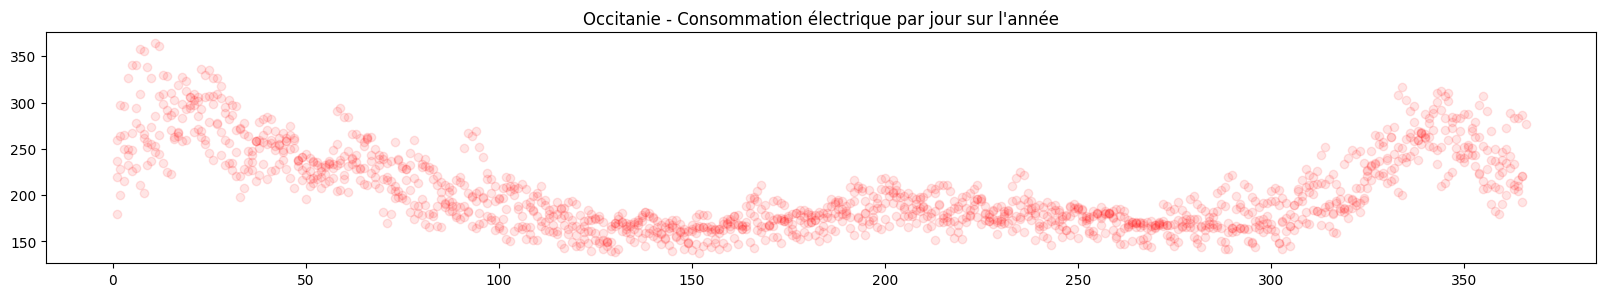

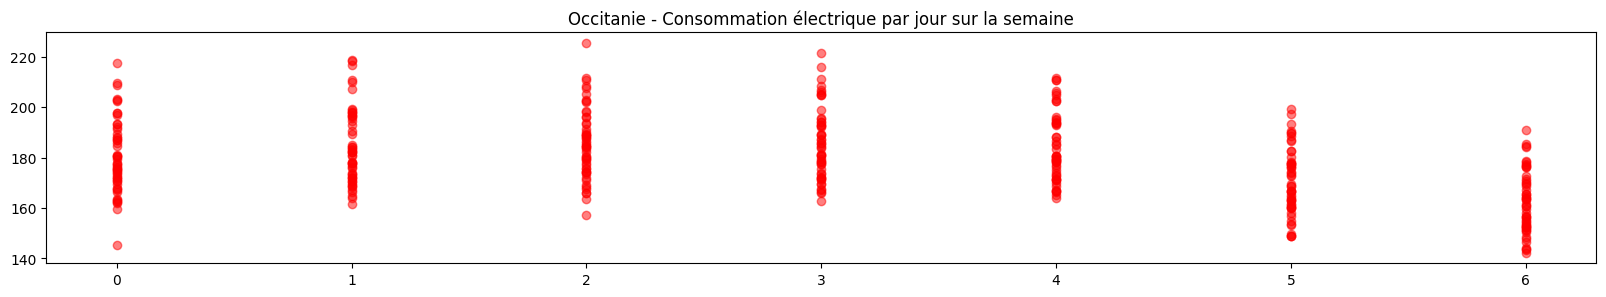

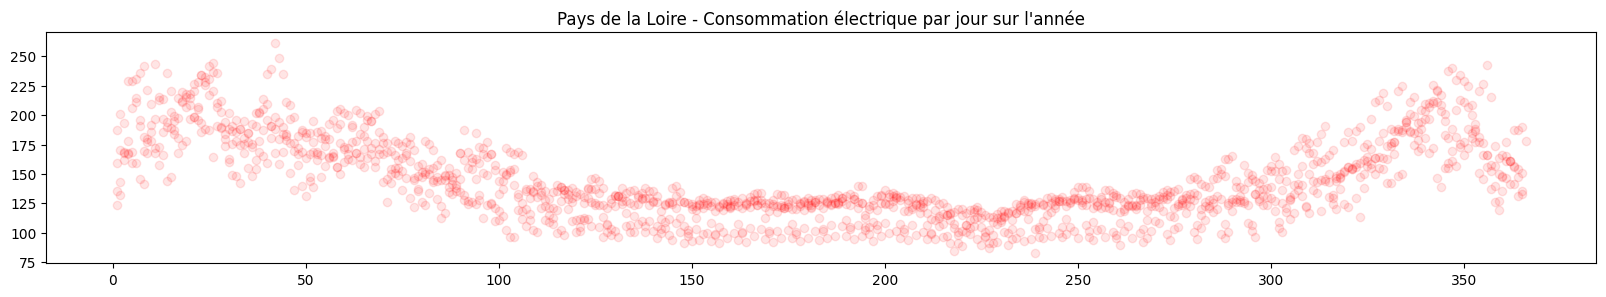

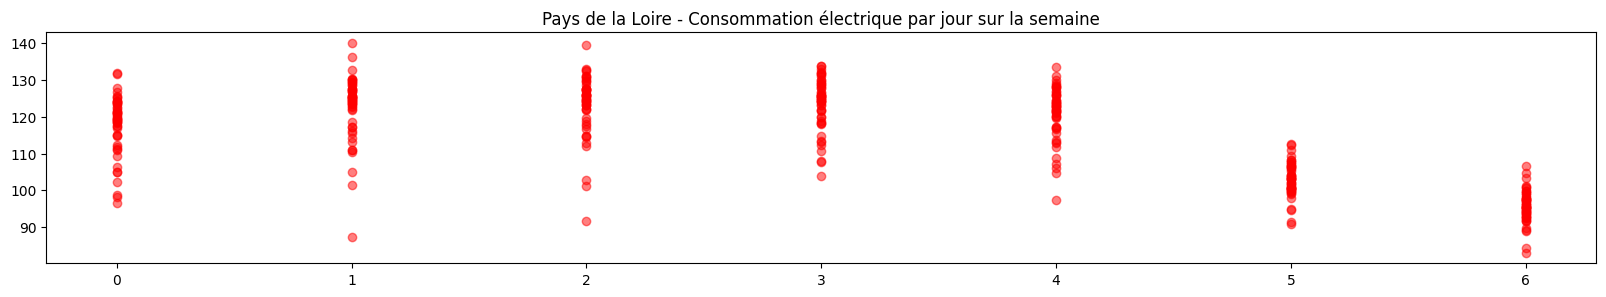

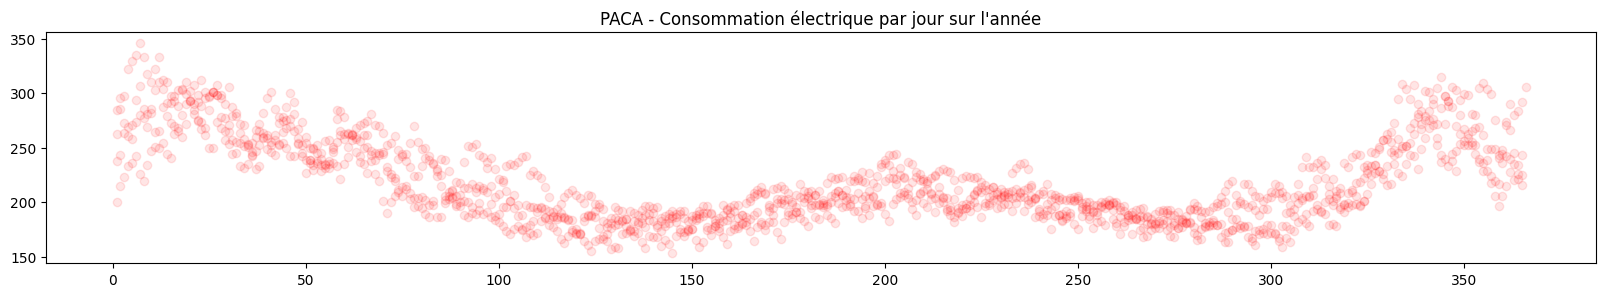

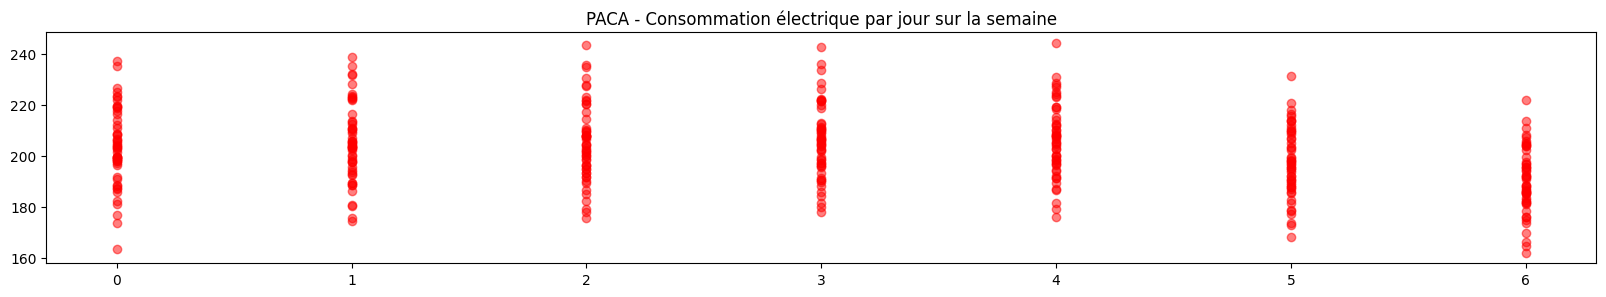

In [45]:


for region, deps in regions_departements.items():

    energyData = pd.read_csv(getFileNameEnr("cleaned", region=region), parse_dates=["Date"])
    energyData = energyData.sort_values("Date")
    energyData = energyData.groupby("Date")["Consommation"].sum().reset_index()

    energyDataSummer = energyData[(energyData['Date'].dt.month >= 6) & (energyData['Date'].dt.month <= 8)]
    
    plt.title(f"{region} - Consommation électrique par jour sur l'année")
    plt.scatter(energyData['Date'].dt.dayofyear,energyData["Consommation"],color="red",alpha=0.1)
    plt.show()

    plt.title(f"{region} - Consommation électrique par jour sur la semaine")
    plt.scatter(energyDataSummer['Date'].dt.dayofweek,energyDataSummer["Consommation"],color="red",alpha=0.5)
    plt.show()


En été les jours de la semaine sont très importants pour la consommation d'énergie en **Bretagne** mais pas partout

In [9]:
#* Premier essai ML 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import columnsTransforme

In [57]:
def getAvgRegion(depMeteos):
    departementUnited = pd.concat(depMeteos)
    regionAverage = departementUnited.groupby("DATE").mean().reset_index()
    regionAverage.drop(columns=["FF2M","NUM_POSTE"],inplace=True) #* Often not complet and redondant with FFM
    return regionAverage

def combineEnrAndMet(energyData,regionAverage):
    energyData =  energyData.groupby("Date").sum().reset_index().drop(["Heures"],axis=1)
    return energyData.merge(regionAverage,"inner",left_on="Date",right_on="DATE").drop(['DATE'],axis=1)

def getTestTrain(combineData,separatingDate):

    trainData = combineData[combineData['Date']<separatingDate]
    testData = combineData[combineData['Date']>=separatingDate]

    Xtrain = trainData.drop(["Date", "Consommation"], axis=1)
    yTrain = trainData[["Consommation"]]
    Xtest  = testData.drop(["Date", "Consommation"], axis=1)
    yTest  = testData[["Consommation"]]

    return Xtrain,yTrain,Xtest,yTest


Ici on a interpolé les données pour la valeur manquante, **peux être intéressant de garder en tête**

In [58]:
degree = 2
featuresName = ['RR','TN', 'TX', 'TM', 'TNSOL', 'TN50', 'DG', 'FFM', 'DRR']
poly = PolynomialFeatures(degree)
linReg = LinearRegression()
linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
# poly = PolynomialFeatures(degree)
# linReg = LinearRegression()

# linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
for region,deps in regions_departements.items():
    combineData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineData,"2023-01-01")

    linRegPipe.fit(Xtrain,yTrain)

    print(region," - score : ",linRegPipe.score(Xtest,yTest))
    # plt.plot(combineData["Date"],linRegPipe.predict(X),label="Prediction")
    # plt.plot(combineData["Date"],y,label="Truth")
    # plt.title(region)
    # plt.legend()
    # plt.show()

Auvergne-Rhône-Alpes  - score :  0.6952447245634965
Bourgogne-Franche-Comté  - score :  0.7301498848139221
Bretagne  - score :  0.8086883270592785
Centre-Val de Loire  - score :  0.8324572778542614
Grand Est  - score :  0.6195294698878261
Hauts-de-France  - score :  0.7094545105770562
Ile-de-France  - score :  0.7945814768314232
Nouvelle-Aquitaine  - score :  0.8005195828383622
Normandie  - score :  0.8054064414035744
Occitanie  - score :  0.8188918710886965
Pays de la Loire  - score :  0.7264467113132802
PACA  - score :  0.7835285316002709


Pour Auvergne-Rhône-Alpes
   param_poly__degree  mean_test_score
0                   1         0.511136
1                   2         0.655140
2                   3         0.240448
Best score : 0.6952
Pour Bourgogne-Franche-Comté
   param_poly__degree  mean_test_score
0                   1         0.592785
1                   2         0.616374
2                   3        -0.082627
Best score : 0.7301
Pour Bretagne
   param_poly__degree  mean_test_score
0                   1          0.53465
1                   2          0.65593
2                   3       -198.64783
Best score : 0.8087
Pour Centre-Val de Loire
   param_poly__degree  mean_test_score
0                   1         0.518268
1                   2         0.674712
2                   3        -2.562843
Best score : 0.8325
Pour Grand Est
   param_poly__degree  mean_test_score
0                   1         0.491115
1                   2         0.512250
2                   3        -0.759973
Best score : 0.6195
Pour Hauts-

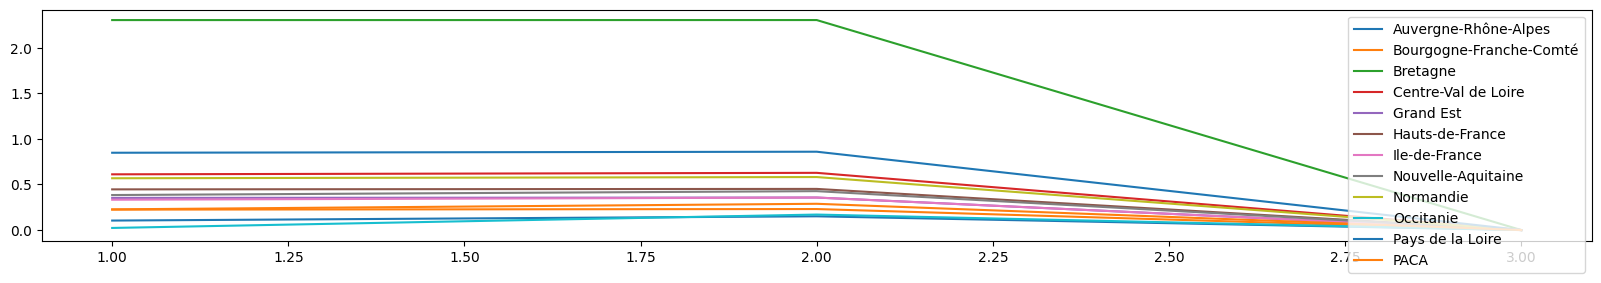

In [38]:
maxSplits = 20
kmax = 3

param_grid = {"poly__degree": list(range(1, kmax + 1))}
poly = PolynomialFeatures(degree)
linReg = LinearRegression()
linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])

for region,deps in regions_departements.items():
    combineData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineData,"2023-01-01")

    grid_search = GridSearchCV(estimator = linRegPipe, param_grid = param_grid, cv = 5, n_jobs=-1)

    grid_search.fit(Xtrain, yTrain)

    searchResults =  pd.DataFrame(grid_search.cv_results_)

    plt.plot(searchResults["param_poly__degree"],np.log10(searchResults["mean_test_score"]-searchResults["mean_test_score"].min()+1),label=region)
    print(f"Pour {region}")
    print(searchResults[["param_poly__degree","mean_test_score"]])
    print(f"Best score : {grid_search.best_estimator_.score(Xtest, yTest):.4f}")

plt.legend()
plt.show()



[0.76726548]


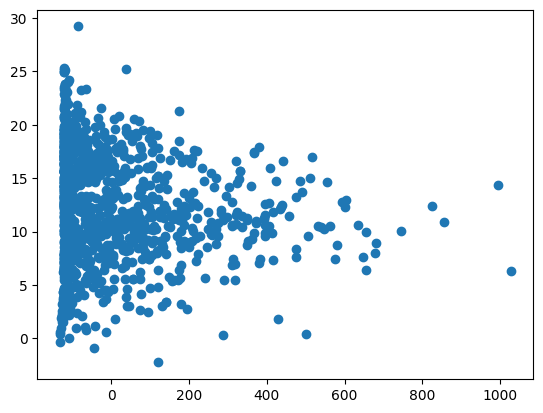

In [ ]:
#* Trying reduce dimension with PCA

d = 2

pca = PCA(d)

# pca.fit(features)
# pca.explained_variance_


pcaLinRegPipe = Pipeline([("pca",pca)]+linRegPipe.steps)
pcaLinRegPipe.fit(Xtrain,yTrain)
pcaLinRegPipe.score(Xtest,yTest)
# pcaLinRegScores = cross_val_score(pcaLinRegPipe,Xtrain,yTrain,cv=400)
# print(f"mean : {pcaLinRegScores.mean()}, var : {pcaLinRegScores.var()}")
# print(f"coef : {pcaLinRegPipe["linReg"].coef_}")

XPca = pca.fit_transform(features)

print(pca.explained_variance_ratio_)
plt.scatter(XPca,XSimple)
plt.show()
# xMin = min(pca.fit_transform(features))
# xMax = max(pca.fit_transform(features))
# xMin,xMax

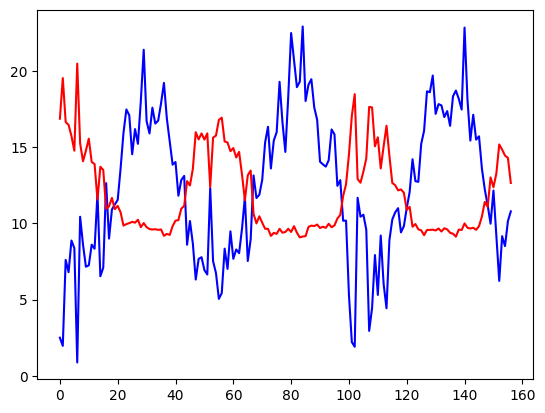

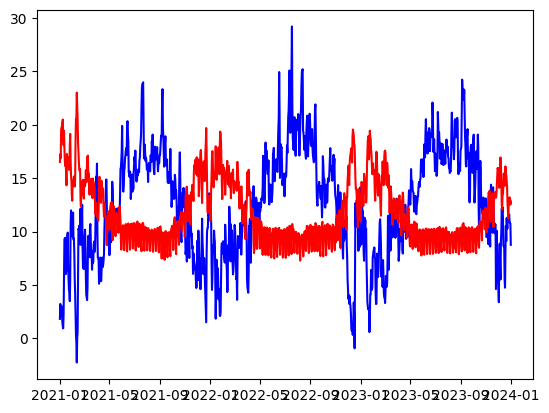

,year,weekNb,Date,Consommation,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR
0,2020,53,2021-01-02,16.872500,-0.054229,5.850249,2.498485,-3.174603,-2.239394,197.398589,0.900000,218.193122
1,2021,1,2021-01-07,19.542271,-0.758849,5.685075,1.961768,-4.095238,-3.242857,294.816540,0.907143,78.646429
2,2021,2,2021-01-14,16.653529,5.176972,10.144776,7.603886,2.659184,3.528571,16.160242,1.950000,209.721429
3,2021,3,2021-01-21,16.467814,4.416844,9.782729,6.801732,2.051701,2.818182,20.534926,2.335714,330.638095
4,2021,4,2021-01-28,15.735000,6.627292,11.105117,8.876407,4.896599,5.566234,30.813966,2.603571,439.926984
...,...,...,...,...,...,...,...,...,...,...,...,...
152,2023,48,2023-11-30,15.182914,3.429314,9.611874,6.225788,0.674026,1.918182,38.415261,1.389286,256.347619
153,2023,49,2023-12-07,14.846071,6.459740,12.174397,9.163265,4.413636,5.344156,12.507009,2.653571,319.619048
154,2023,50,2023-12-14,14.451571,6.219109,11.331911,8.509833,3.570779,4.905195,27.661594,1.514286,93.128571
155,2023,51,2023-12-21,14.302671,8.228386,11.963265,10.150835,6.836364,7.820779,0.000000,2.646429,153.395238


In [ ]:
#* Test lissage par semaine

combineData["weekNb"] = combineData["Date"].dt.isocalendar().week
combineData["year"] = combineData["Date"].dt.isocalendar().year

weekCombineData = combineData.groupby(["year",'weekNb']).mean().reset_index().sort_values(['year','weekNb'])
plt.plot(weekCombineData.index,weekCombineData["TM"],color="blue")
plt.plot(weekCombineData.index,weekCombineData["Consommation"],color="red")
plt.show()

plt.plot(combineData['Date'],combineData["TM"],color="blue")
plt.plot(combineData['Date'],combineData["Consommation"],color="red")
plt.show()
weekCombineData

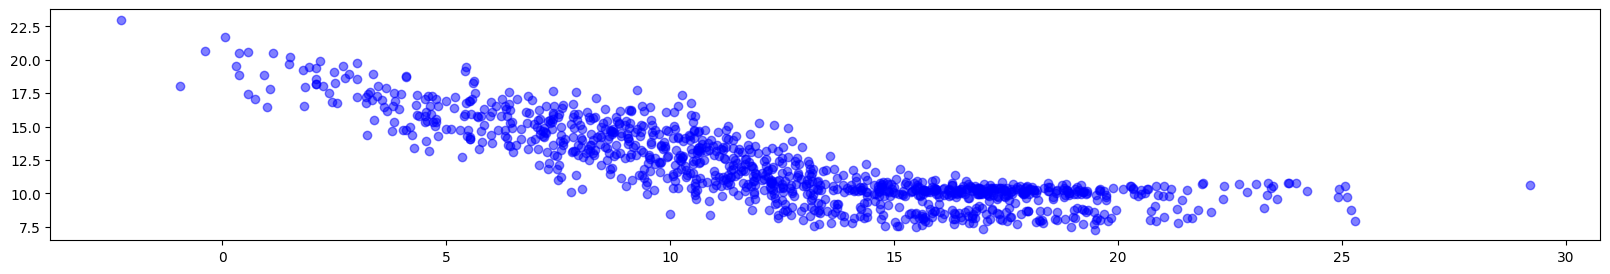

In [35]:
plt.scatter(combineData['TM'],combineData["Consommation"],color="blue",alpha=0.5)
plt.show()

**Test en ajoutant les consommations des derniers jours**

In [41]:
def addLastDays(combineData:pd.DataFrame,nbDays:int=5) -> pd.DataFrame:
    combinedShifted = combineData["Consommation"].shift(list(range(1,nbDays+1)))
    combinedAugmented = combineData.merge(combinedShifted,left_index=True,right_index=True)
    combinedAugmented = combinedAugmented.dropna().reset_index(drop=True) #* We drop the first row because they dont have previous consommation
    return combinedAugmented

In [58]:
combinedShifted = combineData["Consommation"].shift([1,2,3,4,5])
combinedShifted = combineData.merge(combinedShifted,left_index=True,right_index=True)
combinedShifted = combinedShifted.dropna().reset_index(drop=True) #* We drop the first row because they dont have previous consommation
combinedShifted

,Date,Consommation,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR,Consommation_1,Consommation_2,Consommation_3,Consommation_4,Consommation_5
0,2021-01-06,19.8960,-0.023881,5.725373,2.182812,-3.285714,-2.290909,206.203704,0.500,16.200000,19.7384,19.5148,16.8716,17.2333,16.5126
1,2021-01-07,20.2171,-1.185075,6.294030,1.509091,-4.728571,-4.190909,428.576923,0.350,0.000000,19.8960,19.7384,19.5148,16.8716,17.2333
2,2021-01-08,20.4806,-1.686567,5.594030,1.142424,-5.280952,-4.763636,490.763636,0.525,88.000000,20.2171,19.8960,19.7384,19.5148,16.8716
3,2021-01-09,18.8735,-2.879104,5.235821,0.933333,-6.785714,-5.727273,500.283019,1.375,0.000000,20.4806,20.2171,19.8960,19.7384,19.5148
4,2021-01-10,18.0755,-0.917910,6.388060,2.250000,-4.980952,-3.863636,343.436364,0.925,0.000000,18.8735,20.4806,20.2171,19.8960,19.7384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1085,2023-12-27,13.0967,10.071429,13.106494,11.606494,9.054545,9.736364,0.000000,3.925,159.222222,12.5922,11.2082,11.8459,12.6796,14.1239
1086,2023-12-28,13.1999,9.635065,12.889610,11.029870,7.940909,9.181818,0.000000,3.375,65.300000,13.0967,12.5922,11.2082,11.8459,12.6796
1087,2023-12-29,13.1522,9.820779,13.058442,10.805195,8.050000,9.127273,0.000000,2.700,105.111111,13.1999,13.0967,12.5922,11.2082,11.8459
1088,2023-12-30,12.5215,8.124675,12.955844,10.751948,5.809091,6.909091,0.000000,3.375,393.625000,13.1522,13.1999,13.0967,12.5922,11.2082


[]

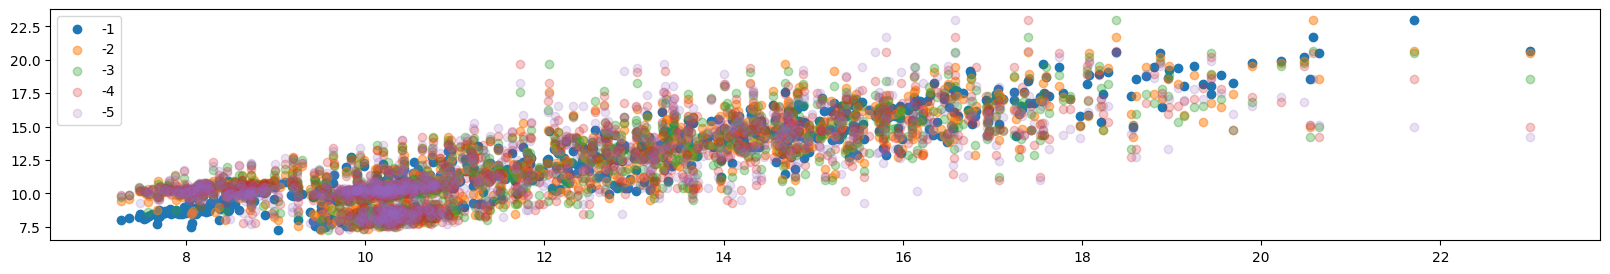

In [45]:

#* Correlation entre la consommation et celle des jours antérieurs
for d in [1,2,3,4,5]:
    plt.scatter(combinedShifted["Consommation"],combinedShifted[f'Consommation_{d}'],label=f"-{d}",alpha=1/d)
plt.legend()
plt.plot()

In [49]:
degree = 2
poly = PolynomialFeatures(degree)

linReg = LinearRegression()

linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])

for region,deps in regions_departements.items():
    combineData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

    combineLastDay = addLastDays(combineData,5)
    # print(combineLastDay)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineLastDay,"2023-01-01")

    linRegPipe.fit(Xtrain,yTrain)

    print(region," - score : ",linRegPipe.score(Xtest,yTest))

# features = combineData.drop(["Date","Consommation"],axis=1).to_numpy()
# trainInd = combinedShifted[combinedShifted['Date']<"2023-01-01"].index
# testInd = combinedShifted[combinedShifted['Date']>="2023-01-01"].index
# print(testInd)
# X = combinedShifted.drop(["Date","Consommation"],axis=1).to_numpy()
# features = combineData[['TM']].to_numpy()
# y = combinedShifted[["Consommation"]].to_numpy()

# X = poly.fit_transform(features)
# Xtrain,Xtest, yTrain, yTest = train_test_split(features,y,test_size=0.2)
# Xtrain = X[trainInd]
# yTrain = y[trainInd]
# Xtest = X[testInd]
# yTest = y[testInd]
# linRegPipe.fit(Xtrain,yTrain)


# print(f'The regression coef {linReg.coef_}')
# print(f'The R^2 determination coef {linReg.score(Xtest,yTest)}')    
# print(f'The RSS {mean_squared_error(yTest,linReg.predict(Xtest))}')    

# linReg.score(XtrainPoly,yTrain)
# X.shape, y.shape
# regionAverage.tail(), energyData.tail()
# combineData
# print("score : ",linRegPipe.score(Xtest,yTest))
# plt.plot(combinedShifted["Date"],linRegPipe.predict(X),label="Prediction")
# plt.plot(combinedShifted["Date"],y,label="Truth")
# plt.legend()
# plt.show()

Auvergne-Rhône-Alpes  - score :  0.9134514025080931
Bourgogne-Franche-Comté  - score :  0.9151799590887301
Bretagne  - score :  0.9248070550570586
Centre-Val de Loire  - score :  0.9278130534559896
Grand Est  - score :  0.9071914777963135
Hauts-de-France  - score :  0.8827896047281744
Ile-de-France  - score :  0.9473109051801323
Nouvelle-Aquitaine  - score :  0.9312396907046057
Normandie  - score :  0.9202231463914066
Occitanie  - score :  0.9461193188662341
Pays de la Loire  - score :  0.9125043031274807
PACA  - score :  0.9566559356903178


**En ajoutant les jours de la semaine et les jours de l'année**

In [ ]:
from sklearn.preprocessing import SplineTransformer #* Sincos augmented
from sklearn.model_selection import TimeSeriesSplit #* to split on time

In [52]:
def sin_transformer(period):
    return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi))


def cos_transformer(period):
    return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi))

In [53]:
def addDays(combineData:pd.DataFrame) -> pd.DataFrame:
    combineDataDays = combineData.copy()
    combineDataDays["weekDay"] = combineDataDays["Date"].dt.day_of_week
    combineDataDays["yearDay"] = combineDataDays["Date"].dt.day_of_year
    return combineDataDays



In [63]:
combinedShiftedDay = combinedShifted.copy()
combinedShiftedDay["weekDay"] = combinedShiftedDay["Date"].dt.day_of_week
combinedShiftedDay["yearDay"] = combinedShiftedDay["Date"].dt.day_of_year
combinedShiftedDay

,Date,Consommation,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR,Consommation_1,Consommation_2,Consommation_3,Consommation_4,Consommation_5,weekDay,yearDay
0,2021-01-06,19.8960,-0.023881,5.725373,2.182812,-3.285714,-2.290909,206.203704,0.500,16.200000,19.7384,19.5148,16.8716,17.2333,16.5126,2,6
1,2021-01-07,20.2171,-1.185075,6.294030,1.509091,-4.728571,-4.190909,428.576923,0.350,0.000000,19.8960,19.7384,19.5148,16.8716,17.2333,3,7
2,2021-01-08,20.4806,-1.686567,5.594030,1.142424,-5.280952,-4.763636,490.763636,0.525,88.000000,20.2171,19.8960,19.7384,19.5148,16.8716,4,8
3,2021-01-09,18.8735,-2.879104,5.235821,0.933333,-6.785714,-5.727273,500.283019,1.375,0.000000,20.4806,20.2171,19.8960,19.7384,19.5148,5,9
4,2021-01-10,18.0755,-0.917910,6.388060,2.250000,-4.980952,-3.863636,343.436364,0.925,0.000000,18.8735,20.4806,20.2171,19.8960,19.7384,6,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1085,2023-12-27,13.0967,10.071429,13.106494,11.606494,9.054545,9.736364,0.000000,3.925,159.222222,12.5922,11.2082,11.8459,12.6796,14.1239,2,361
1086,2023-12-28,13.1999,9.635065,12.889610,11.029870,7.940909,9.181818,0.000000,3.375,65.300000,13.0967,12.5922,11.2082,11.8459,12.6796,3,362
1087,2023-12-29,13.1522,9.820779,13.058442,10.805195,8.050000,9.127273,0.000000,2.700,105.111111,13.1999,13.0967,12.5922,11.2082,11.8459,4,363
1088,2023-12-30,12.5215,8.124675,12.955844,10.751948,5.809091,6.909091,0.000000,3.375,393.625000,13.1522,13.1999,13.0967,12.5922,11.2082,5,364


score :  0.9731077311962832


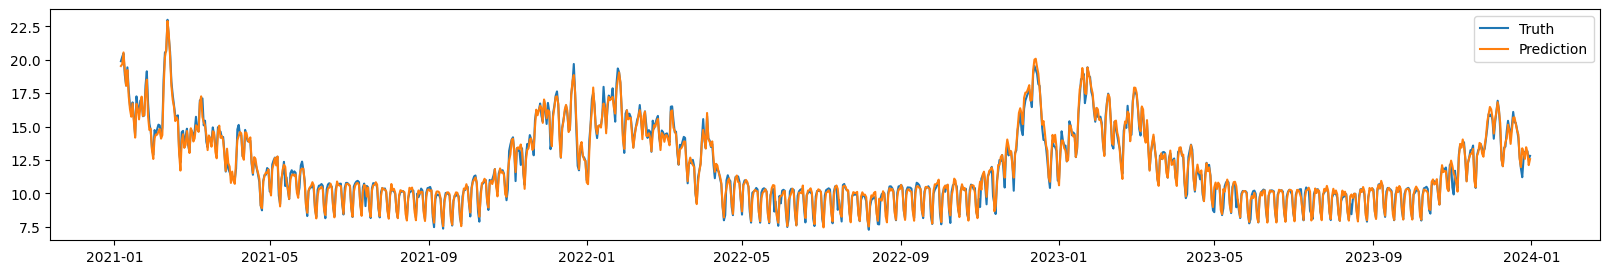

In [99]:
X = combinedShiftedDay.drop(["Date","Consommation"],axis=1)
# features = combineData[['TM']].to_numpy()
y = combinedShiftedDay[["Consommation"]].to_numpy()

sinCosTransformer = ColumnTransformer(
    transformers=[
        ("weekDay","drop",["weekDay"]),
        ("yearDay","drop",["yearDay"]),
        ("weekDaySin",sin_transformer(7),["weekDay"]),
        ("weekDayCos",cos_transformer(7),["weekDay"]),
        ("yearDayCos",cos_transformer(364),["yearDay"]),
        ("yearDaySin",cos_transformer(364),["yearDay"]),
    ],
    remainder='passthrough'
)

sincosLinRegPipe = Pipeline([
    ("transformer",sinCosTransformer),
    ('poly',poly),
    ("linReg",linReg)
])

ts_cv = TimeSeriesSplit( #* To split intelignetly on time
    n_splits=3,
    gap=3,
    max_train_size=10000,
    test_size=150,
)


# X.iloc[train_0]
# X = poly.fit_transform(features)
Xtrain,Xtest, yTrain, yTest = train_test_split(X,y,test_size=0.2)
# Xtrain = X[trainInd]
# yTrain = y[trainInd]
# Xtest = X[testInd]
# yTest = y[testInd]

sincosLinRegPipe.fit(Xtrain,yTrain)
print("score : ",sincosLinRegPipe.score(Xtest,yTest))

plt.plot(combinedShiftedDay["Date"],y,label="Truth")
plt.plot(combinedShiftedDay["Date"],sincosLinRegPipe.predict(X),label="Prediction")
plt.legend()
plt.show()

Auvergne-Rhône-Alpes  - score :  0.9593507928683255
Bourgogne-Franche-Comté  - score :  0.9600444331540278
Bretagne  - score :  0.9728356569055185
Centre-Val de Loire  - score :  0.960322182586349
Grand Est  - score :  0.9502302100579552
Hauts-de-France  - score :  0.94392686144432
Île-de-France  - score :  0.9748732752701309
Nouvelle-Aquitaine  - score :  0.964370247916455
Normandie  - score :  0.9643724849198754
Occitanie  - score :  0.9694134151559523
Pays de la Loire  - score :  0.95740671156283
PACA  - score :  0.9682155589916497


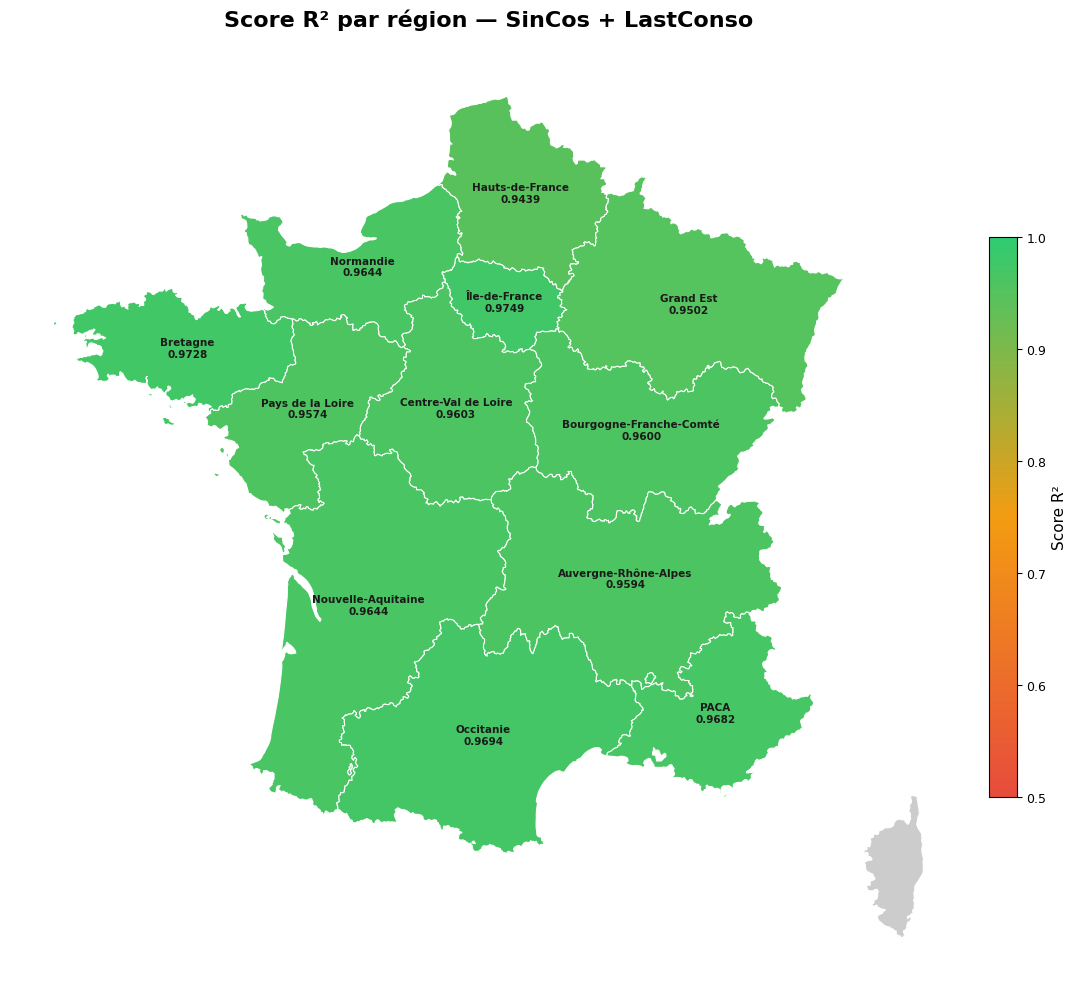

In [72]:

degree = 2
poly = PolynomialFeatures(degree)

linReg = LinearRegression()

sinCosTransformer = ColumnTransformer(
    transformers=[
        ("weekDay","drop",["weekDay"]),
        ("yearDay","drop",["yearDay"]),
        ("weekDaySin",sin_transformer(7),["weekDay"]),
        ("weekDayCos",cos_transformer(7),["weekDay"]),
        ("yearDayCos",cos_transformer(364),["yearDay"]),
        ("yearDaySin",cos_transformer(364),["yearDay"]),
    ],
    remainder='passthrough'
)

sincosLinRegPipe = Pipeline([
    ("transformer",sinCosTransformer),
    ('poly',poly),
    ("linReg",linReg)
])

scores = {}
for region,deps in regions_departements.items():
    combineData = combineEnrAndMet(getEnrData(region),getAvgRegion([getMetData("ByDay",dep) for dep in deps]))

    combineLastDay = addLastDays(combineData,5)

    combineWDays = addDays(combineLastDay)

    # print(combineLastDay)
    Xtrain,yTrain,Xtest,yTest = getTestTrain(combineWDays,"2023-01-01")
    # print(Xtrain, Xtest)
    sincosLinRegPipe.fit(Xtrain,yTrain)

    scores[region] = sincosLinRegPipe.score(Xtest, yTest)
    print(region, " - score : ", scores[region])

createRegionMap(scores, title="Score R² par région — SinCos + LastConso")

**ETUDE PAR HEURE**

In [112]:
def toHour(enrData:pd.DataFrame):
    x_energy = pd.to_datetime(enrData["Date"].astype(str) + " " + enrData["Heures"])
    enrData = enrData.set_index(x_energy).resample("1h").sum(numeric_only=True).reset_index(names=["dateTime"]) #* somme les demi-heure en heure
    enrData["Date"] = pd.to_datetime(enrData["dateTime"].dt.date)
    enrData["Heures"] = enrData["dateTime"].dt.strftime("%H:%M")
    return enrData

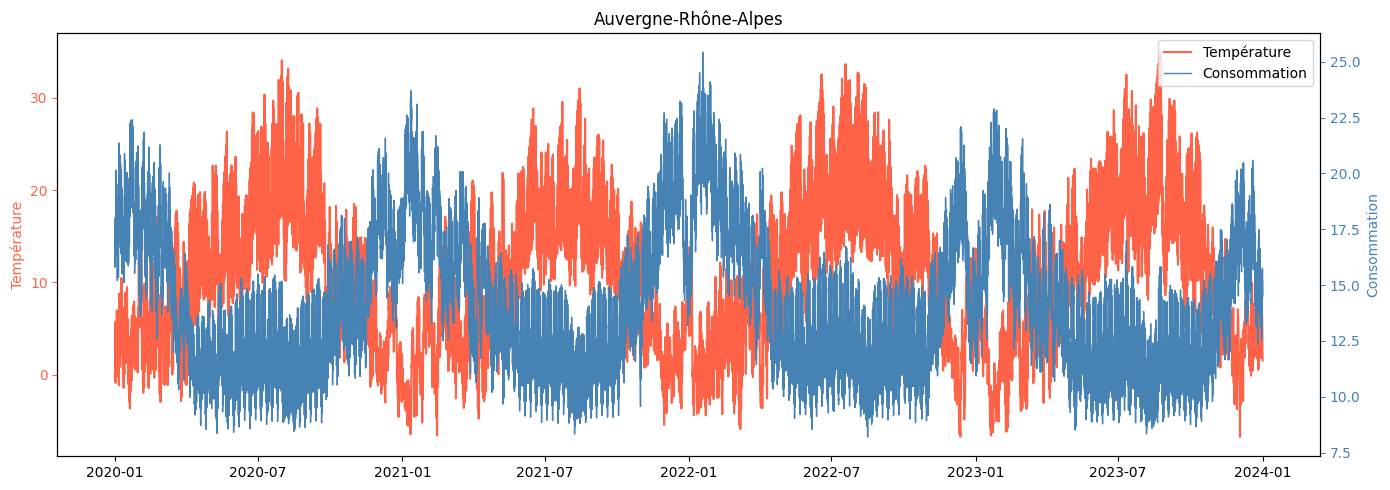

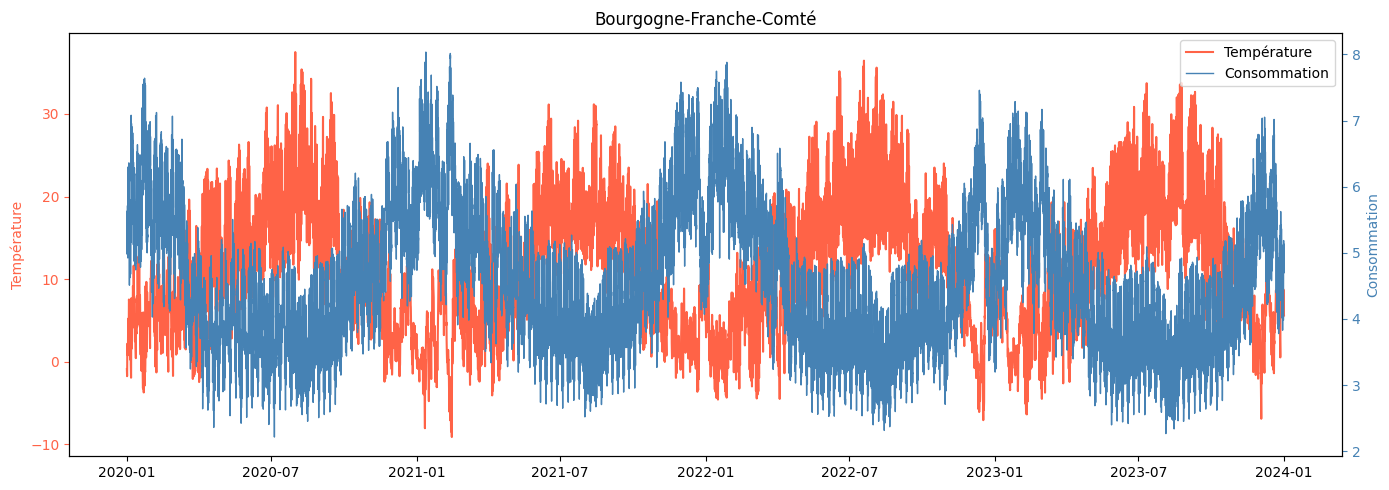

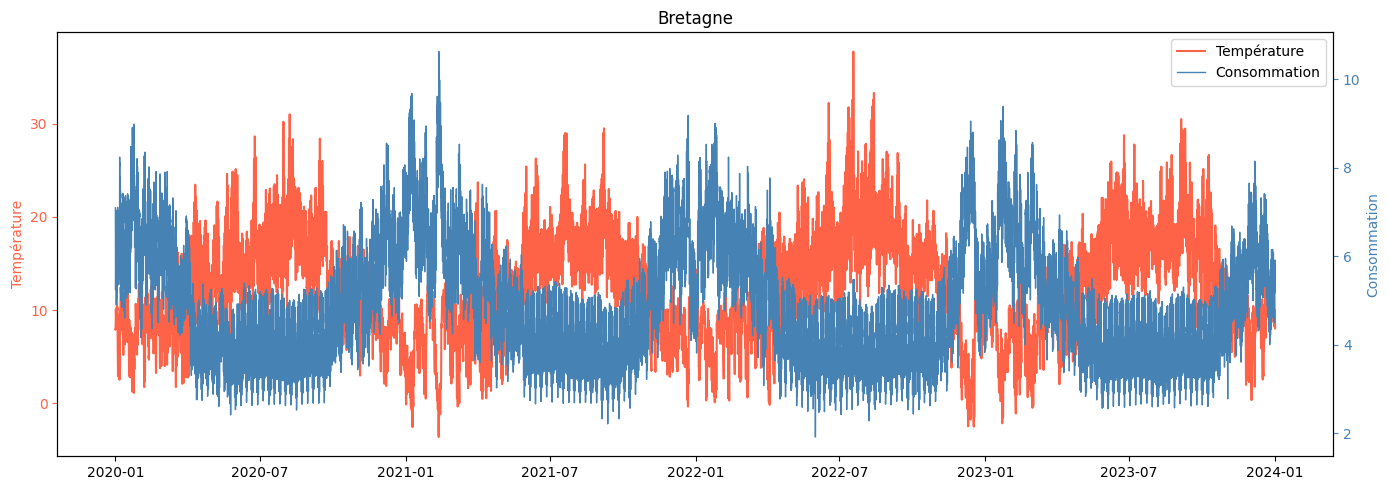

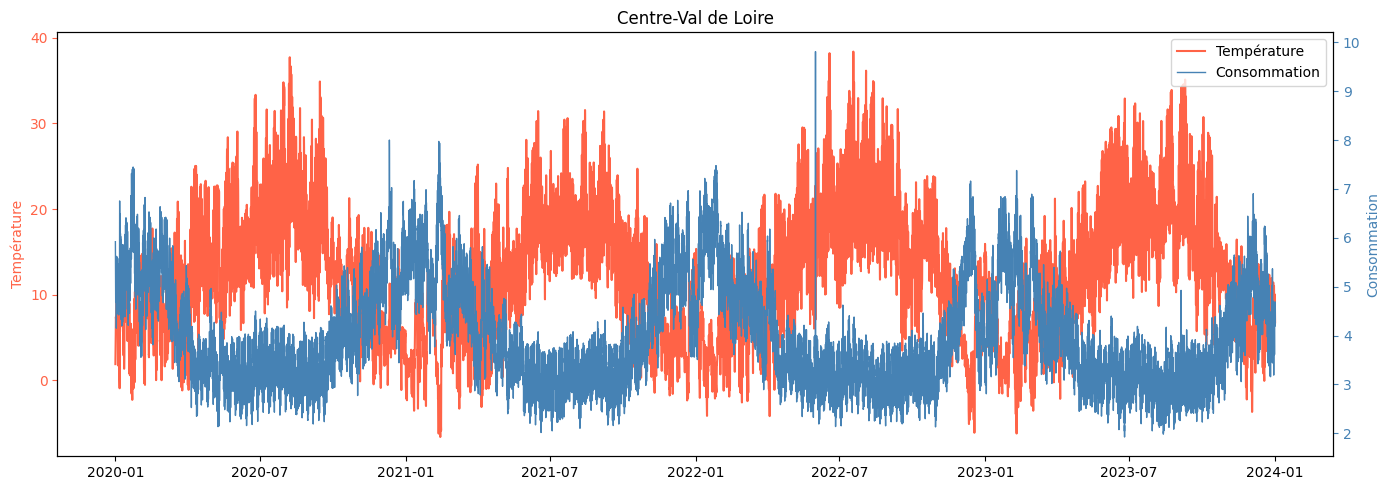

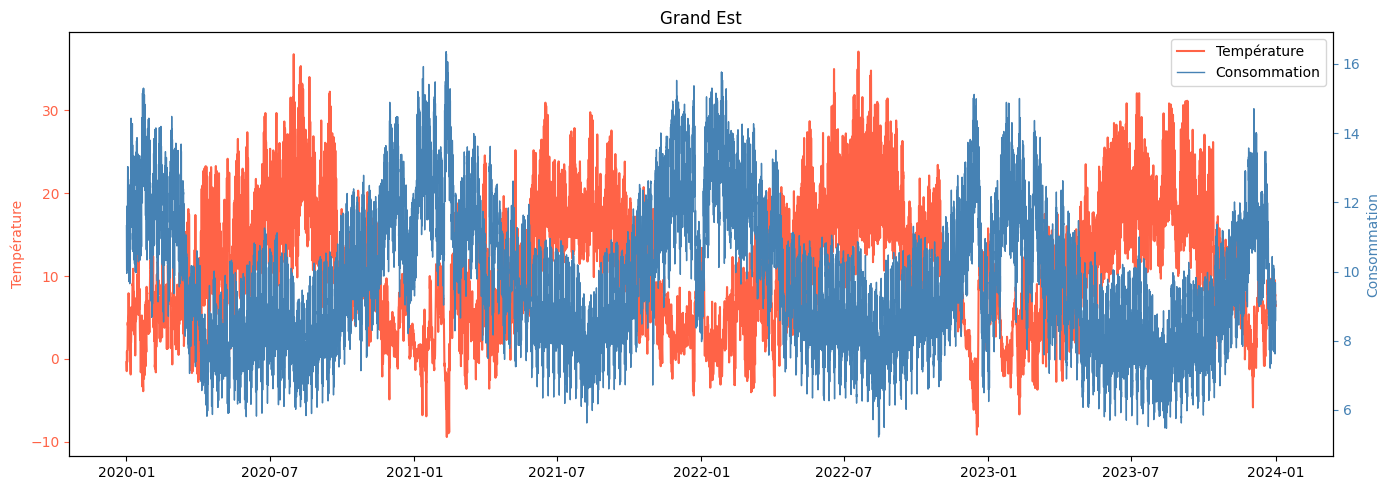

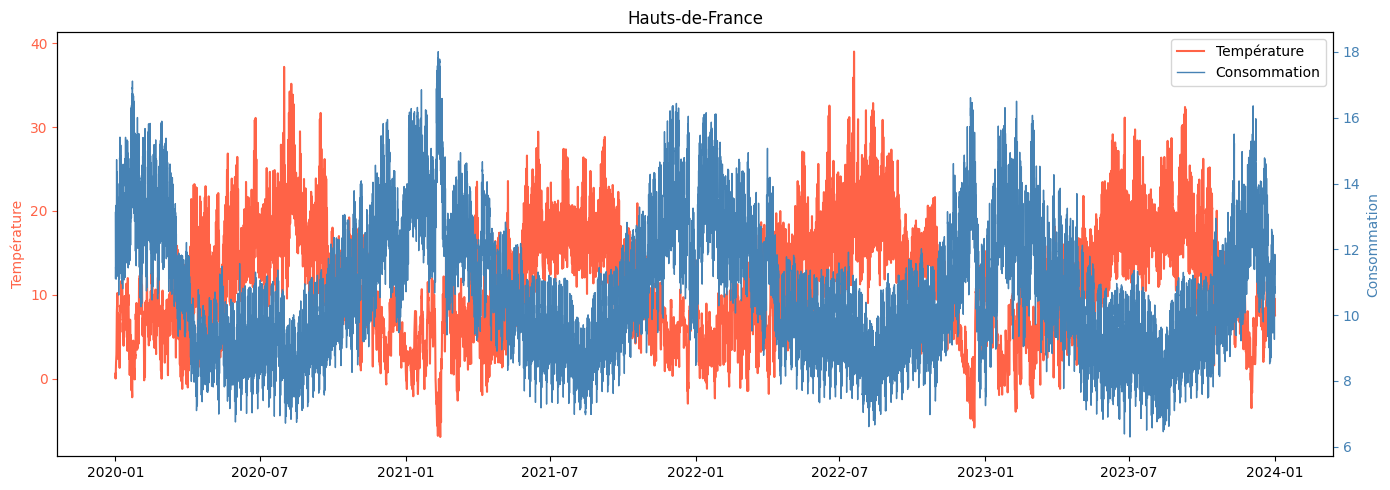

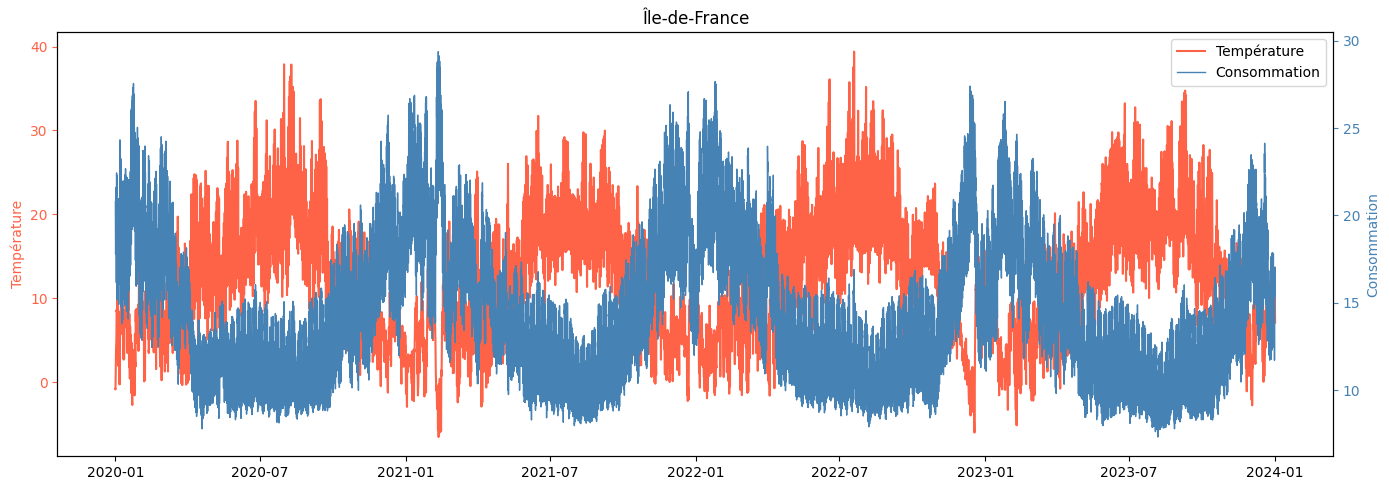

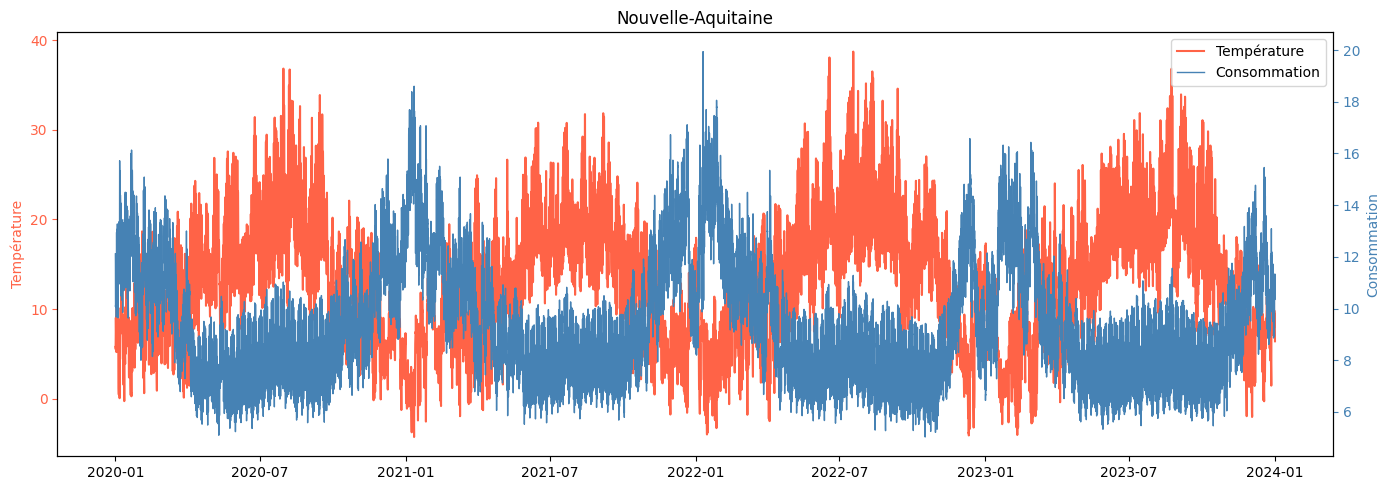

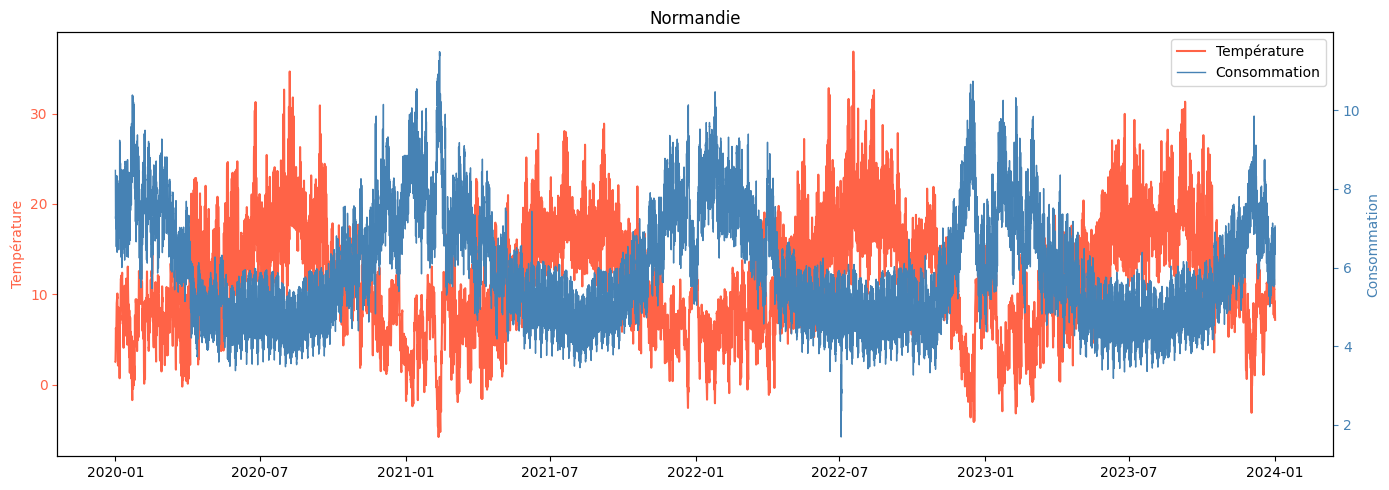

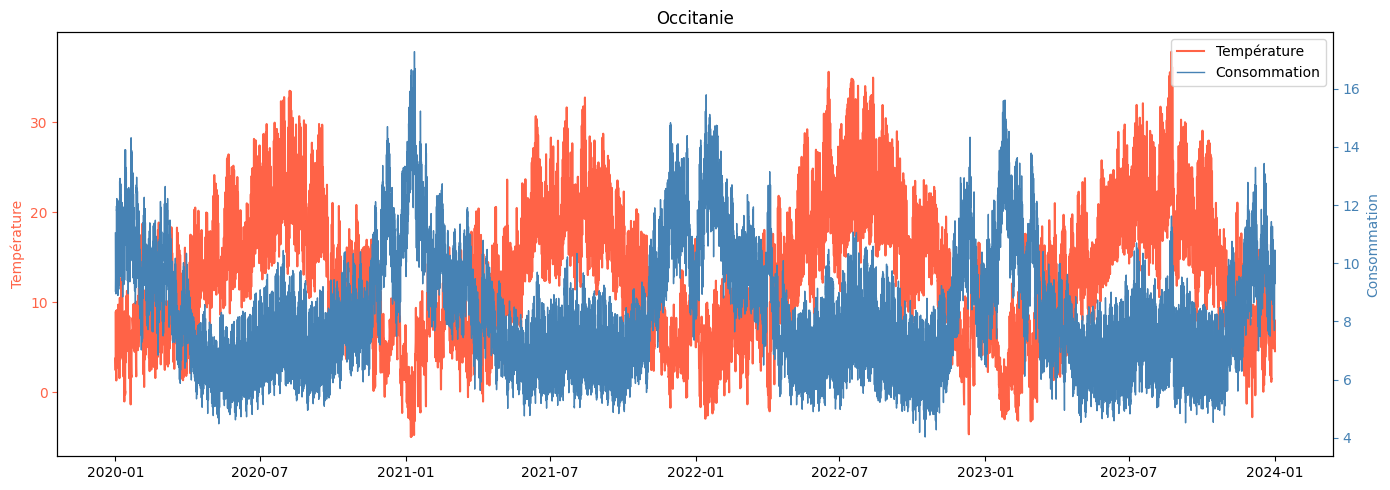

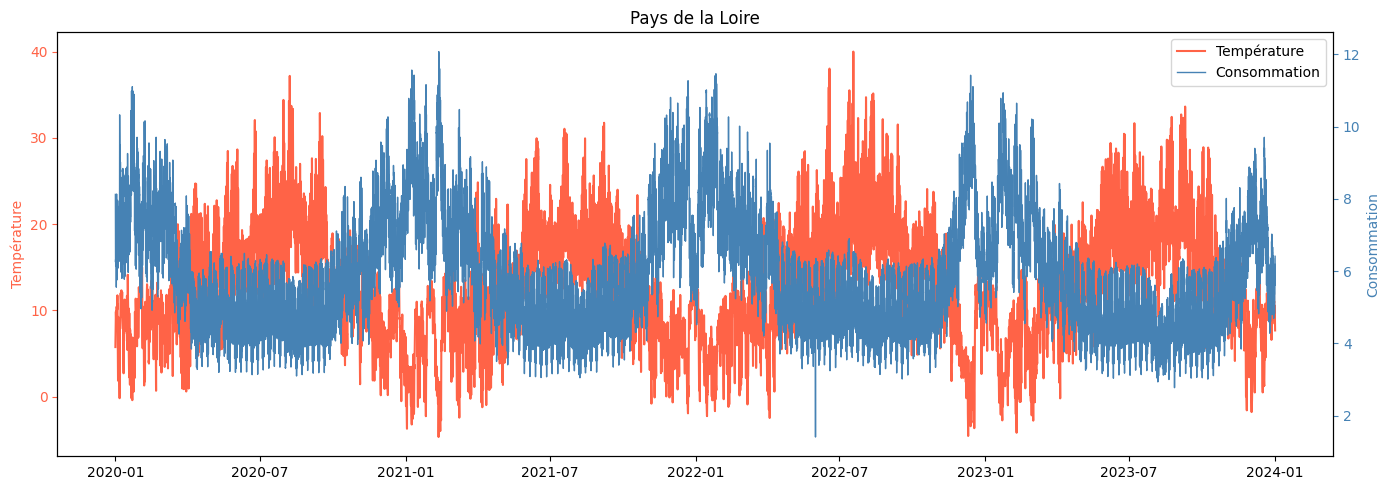

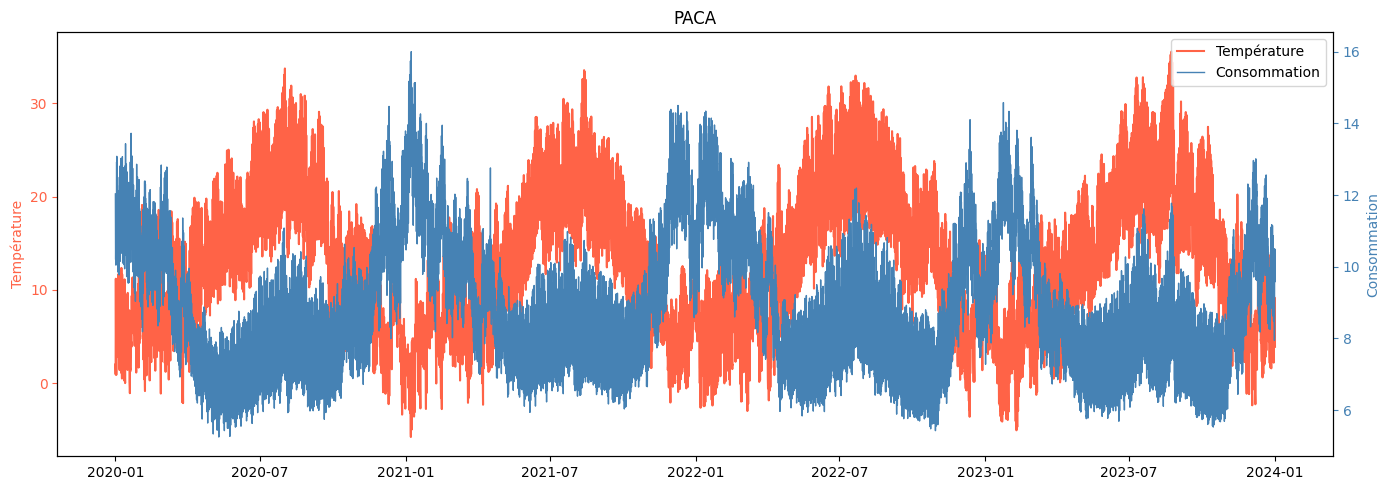

In [114]:
#* Plot consommation - meteo by Hour
for region,deps in regions_departements.items():


    energyData = toHour(getEnrData(region))

    # print(energyData)
    departementsData = []
    for dep in deps: 

        depDf = getMetData("Byhour",dep)
        # print(depDf.dtypes)
        # print(depDf["DATE"])
        # print(energyData.dtypes)
        depDf = depDf[(depDf["DATE"] >= energyData["Date"].min()) & (depDf["DATE"] <= energyData["Date"].max())]
        departementsData.append(depDf)


    departementUnited = pd.concat(departementsData)

    regionAverage = departementUnited.groupby(["DATE","HOUR"],as_index=False).mean() #* moyenne sur les heures

    x_met = pd.to_datetime(regionAverage["DATE"].astype(str)) + pd.to_timedelta(regionAverage["HOUR"], unit="h")

    x_energy = energyData["dateTime"]
    generateDoublePlot(x_met,regionAverage['T'],x_energy,energyData["Consommation"],"Température","Consommation")
    # plt.plot(regionAverage['HOUR'],regionAverage["T"],label="Température",)
    # plt.plot(energyData['Heures'],energyData["Consommation"],label="Consommation",linewidth=0.2)
    # plt.title(region)
    # plt.legend()
    # plt.show()

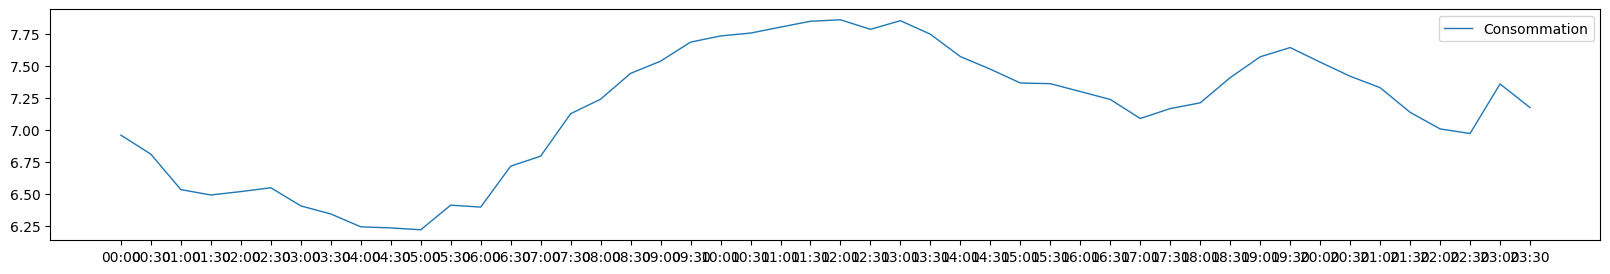

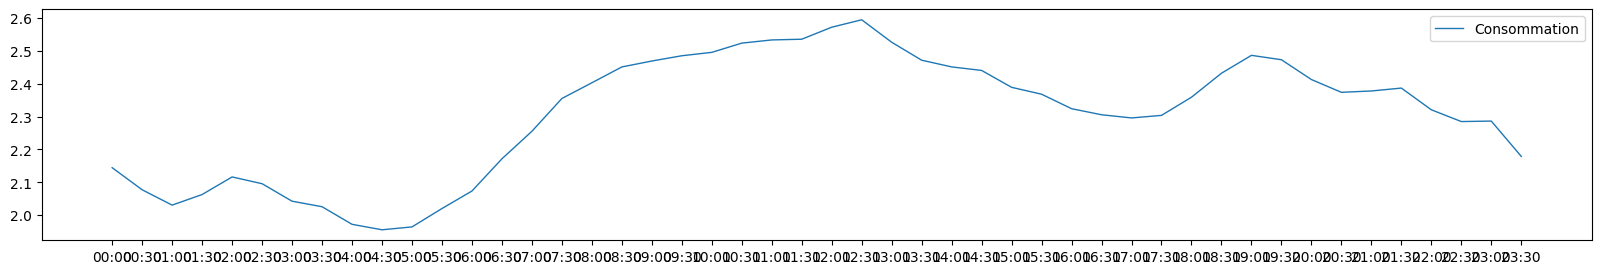

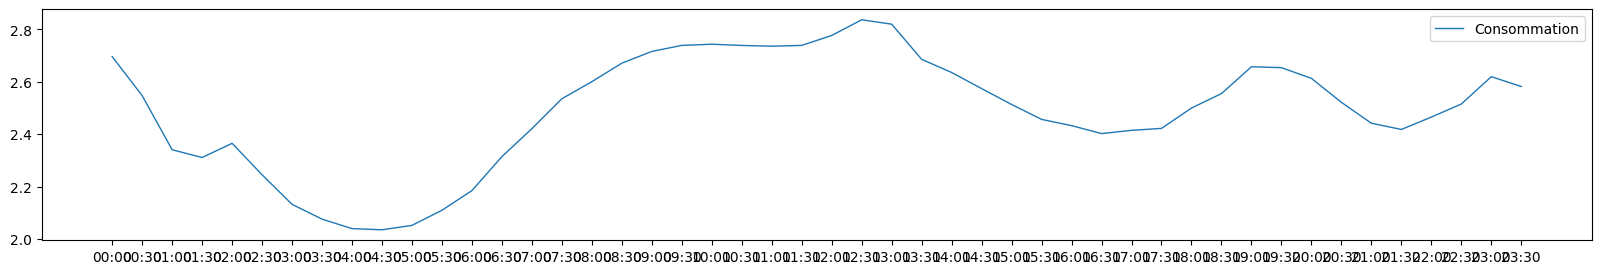

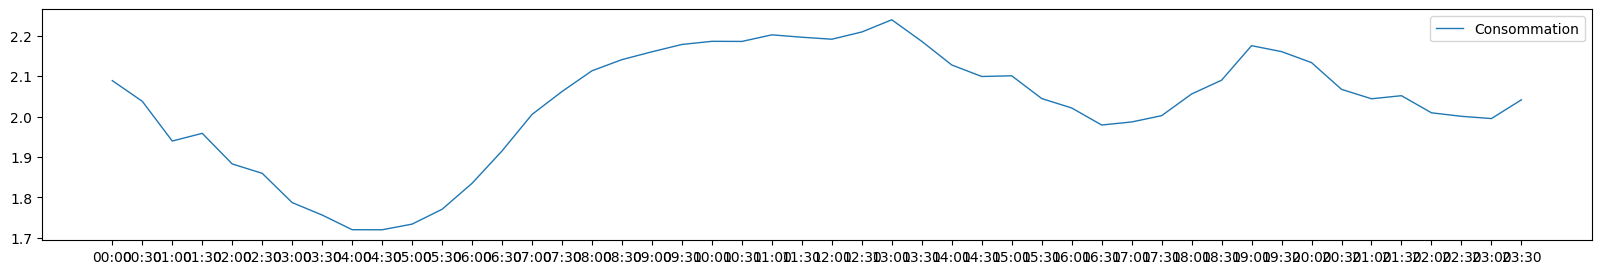

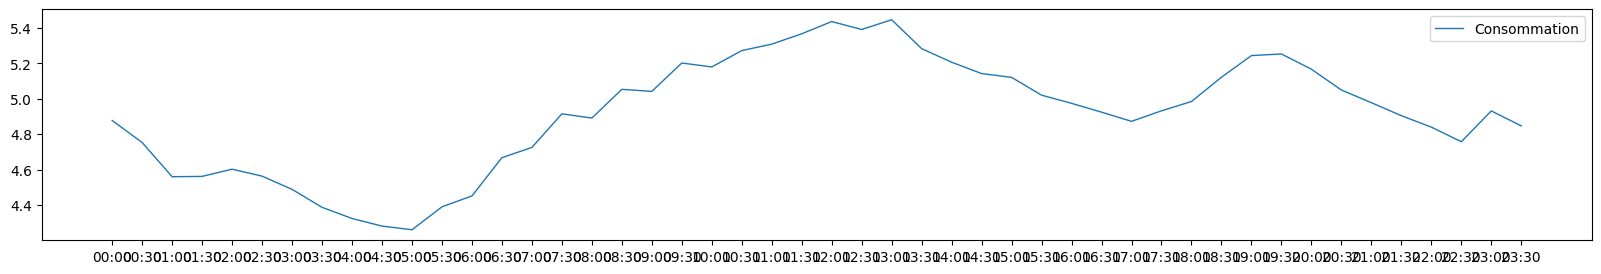

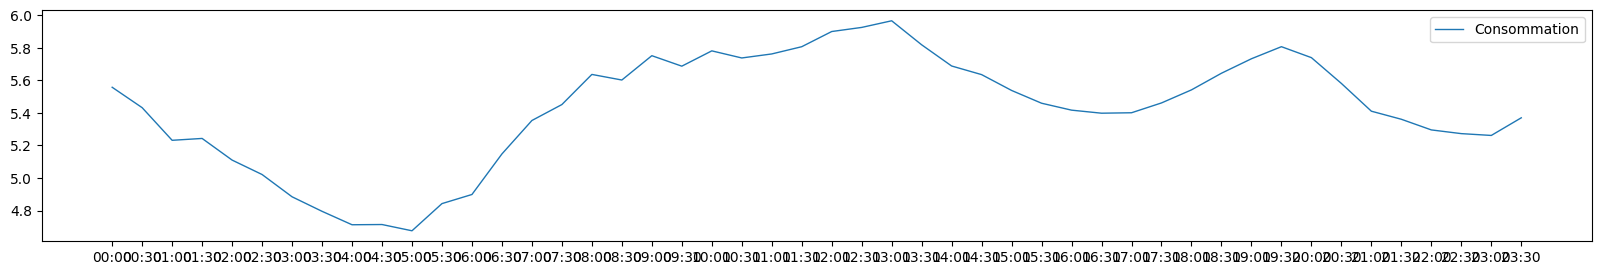

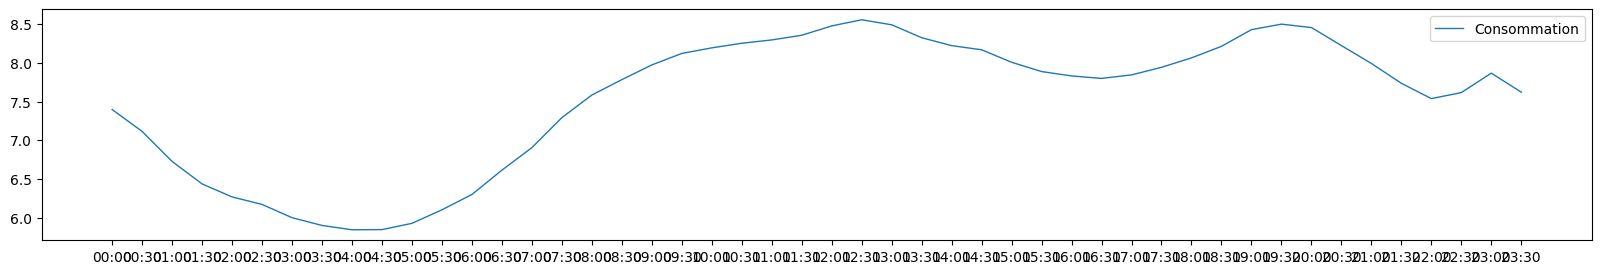

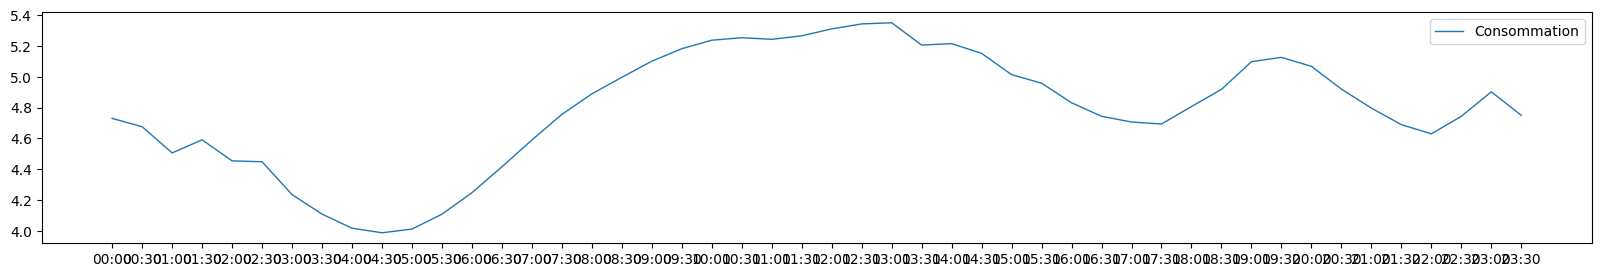

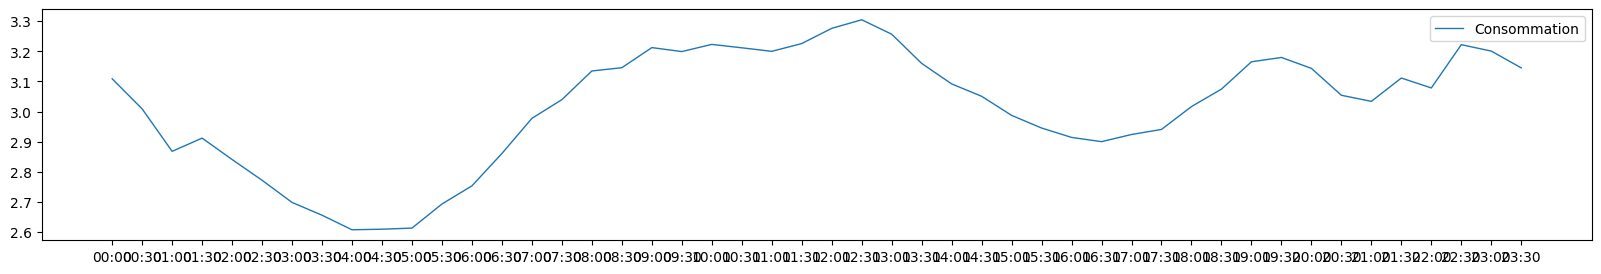

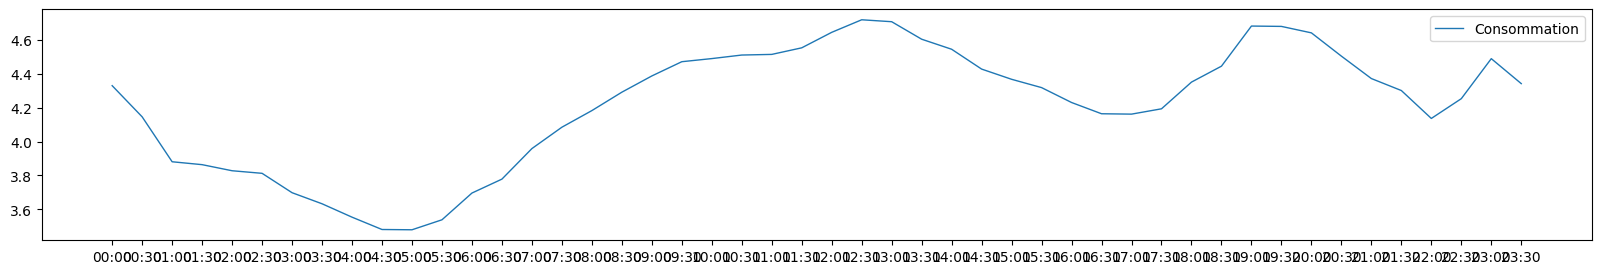

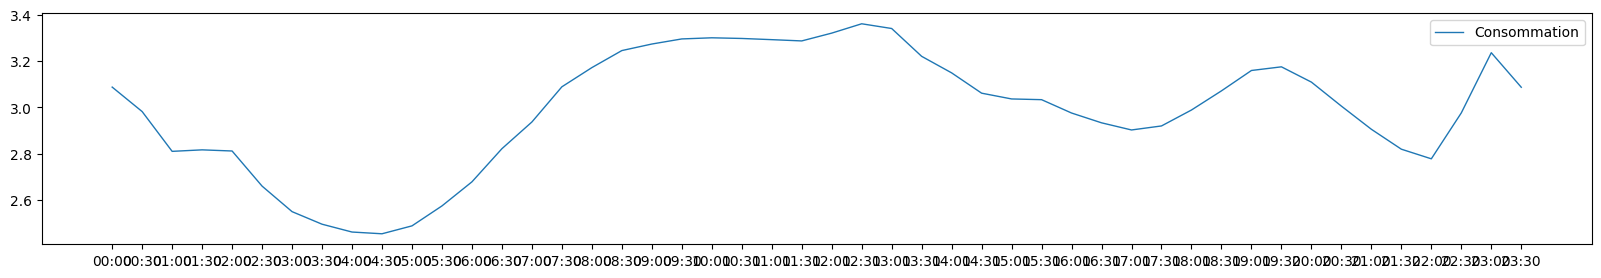

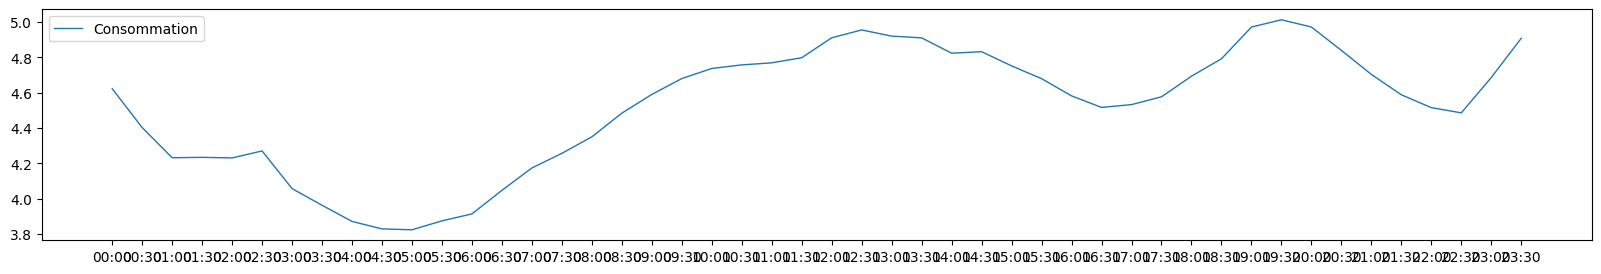

In [ ]:
for region,deps in regions_departements.items():


    energyData = getEnrData(region)
    energyData = energyData.sort_values("Date")

    energyData = energyData.groupby("Heures",as_index=False).mean()

    plt.plot(energyData['Heures'],energyData["Consommation"],label="Consommation",linewidth=1)
    # plt.title(region)
    plt.legend()
    plt.show()

**Calcul des prédiction RTE**

In [75]:
from sklearn.metrics import r2_score

In [76]:
rteEstimation = pd.read_csv(os.path.join("cleanedData","complement","rteEstimation.csv"))

print("Score on J by Hour",r2_score(rteEstimation["Consommation"],rteEstimation["Prévision J"]))
print("Score on J-1 by Hour",r2_score(rteEstimation["Consommation"],rteEstimation["Prévision J-1"]))

rteByDay = rteEstimation.groupby("Date").sum().reset_index()
print("Score on J by Day",r2_score(rteByDay["Consommation"],rteByDay["Prévision J"]))
print("Score on J-1 by Day",r2_score(rteByDay["Consommation"],rteByDay["Prévision J-1"]))

Score on J by Hour 0.9645096436232324
Score on J-1 by Hour 0.9856426341886126
Score on J by Day 0.9612898849696805
Score on J-1 by Day 0.988173421293277
